# Market Risk: Value-at-Risk, Expected Shortfall and Out-of-Sample Backtesting

**A comparative validation study of historical, parametric, Monte Carlo, GARCH/EGARCH and filtered-historical VaR models**

*Author: Nasser Kassioui — MSc Applied Mathematics & Statistics (Quantitative Finance), Université de Bordeaux*

---

**Contents**

1. Executive Summary
2. Research Question and Methodology
3. Data Acquisition and Exploratory Analysis
4. Historical VaR and Expected Shortfall
5. Parametric VaR: Gaussian and Student-t
6. Monte Carlo Simulation
7. GARCH and EGARCH Models
8. Out-of-Sample Backtesting
9. Comparative Model Evaluation
10. Adaptive Hybrid VaR: Quantitative Extension
11. Conclusions and Limitations
12. References

## 1. Executive Summary

**Objective.** Compare nine one-day VaR/ES models — historical simulation, unconditional Gaussian and Student-t, Monte Carlo, GARCH(1,1) and EGARCH(1,1) with Gaussian and Student-t innovations, and a filtered-historical *Adaptive Hybrid* — on genuine out-of-sample forecasts, using the validation toolkit of a market-risk backtesting function: Kupiec, Christoffersen, Dynamic Quantile (with exact Monte Carlo p-values), an ES exceedance test, the strictly consistent FZ0 joint VaR–ES score with Diebold–Mariano comparisons, Basel traffic-light zones and an ex-ante calm/stress split.

> **Dataset of the reference run.** The notebook downloads SPY via `yfinance`. The outputs saved in this version were produced in an environment without access to Yahoo Finance, so the loader fell back — with a logged warning — to the daily S&P 500 index series bundled with the `arch` package (1999–2018, 4,030 out-of-sample days from Dec 2002 to Dec 2018, including the 2008 crisis). Every number quoted below comes from that run; re-executing the notebook online regenerates all tables and charts for SPY.

**Key findings (reference run)**

1. **Conditioning on volatility is the first-order effect.** All unconditional models — HS, Gaussian, Student-t and Monte Carlo — fail the independence, conditional-coverage and DQ tests at both confidence levels. Their 99% violation rate rises to 3–7% on days that are ex-ante classified as stressed (nominal 1%), and they record 15–21 violations during the 2008–09 crisis where 1.5 were expected. Every GARCH-type model beats historical simulation on the joint VaR–ES score with Diebold–Mariano significance, except the Gaussian EGARCH at 99%.
2. **The innovation distribution is the second-order effect.** GARCH with Gaussian innovations violates its 99% VaR on 2.2% of days. Student-t innovations bring this down to 1.6%, but the symmetric unit-variance t has thin "shoulders" and over-violates at 95% (6.1%).
3. **Asymmetry did not pay out of sample here.** EGARCH wins clearly on in-sample likelihood criteria but does not beat GARCH-t on out-of-sample scores, and its estimation is fragile: 13–14 of 192 monthly refits had no admissible estimate, and the notebook documents an invertibility failure that `arch`'s internal variance bounds can mask.
4. **The Adaptive Hybrid (GARCH-QMLE volatility × empirical standardised-residual tail) is the best model in this study**, with the lowest FZ0 score at 95% and 99%. It is the only model that passes the Kupiec, Christoffersen-independence and conditional-coverage tests at both levels (50 violations at 99% vs 40.3 expected; 187 at 95% vs 201.5) and holds near-nominal rates in both calm and stressed regimes. Its edge comes from capturing the **negative skew of standardised residuals** (empirical 1% quantile ≈ −2.7 vs −2.33 Gaussian). The gain over GARCH-N is significant at 99% (DM = −3.2), the gain over GARCH-t is not (DM = −1.3, p = 0.20).
5. **No model is "validated" by every test.** The DQ test rejects all models at 99%, the hybrid included (Monte Carlo p = 0.001): violations still cluster at lags 2–4, which Christoffersen's first-order test cannot detect. The ES exceedance test also flags a mild ES underestimation for the hybrid at 95%. These residual weaknesses are reported, not tuned away.
6. **Monte Carlo adds noise, not information,** when an analytical solution exists: the MC Student-t model reproduces the analytical Student-t results to within simulation error.

## 2. Research Question and Methodology

**Research question.** *How do historical, parametric, Monte Carlo and conditional-volatility VaR models compare in terms of risk estimation, out-of-sample coverage, violation clustering and tail-risk forecasting — particularly during periods of market stress?*

### 2.1 Conventions (used everywhere in this notebook)

| Quantity | Definition |
|---|---|
| Log return | $r_t = \ln(P_t / P_{t-1})$, in decimal units (0.01 = 1%) |
| Loss | $L_t = -r_t$ (a positive number is a loss) |
| Confidence level / tail probability | $\alpha \in \{0.95, 0.99\}$, $\;p = 1-\alpha$ |
| Value-at-Risk | $\mathrm{VaR}_{\alpha,t} = -Q_{p}(r_t \mid \mathcal F_{t-1})$, a **positive loss threshold** |
| Expected Shortfall | $\mathrm{ES}_{\alpha,t} = \frac{1}{p}\int_0^{p} \mathrm{VaR}_{1-u,t}\,du$, which equals $\mathbb E[L_t \mid L_t \ge \mathrm{VaR}_{\alpha,t}, \mathcal F_{t-1}]$ for continuous distributions |
| Violation (hit) | $I_t = \mathbb 1\{L_t > \mathrm{VaR}_{\alpha,t}\}$ |

$\mathcal F_{t-1}$ is the information set at the close of day $t-1$. Every forecast for day $t$ is a function of returns up to and including $r_{t-1}$ only.

Because $1 - e^{r}$ is strictly increasing in $-r$, a VaR on log returns maps one-to-one into a VaR on simple returns, $\mathrm{VaR}^{\text{simple}} = 1 - e^{-\mathrm{VaR}^{\log}}$, and **the violation sequence is identical** under either convention. Only the reported magnitudes differ (by less than 0.1 pp at the levels seen here).

### 2.2 Experimental design

* **Chronological, rolling one-day-ahead forecasting.** Let $T_0$ be the first forecast date (the first day with `W_EST` = 1,000 observations of history). For every $t \ge T_0$, each model is estimated on a trailing window ending at $t-1$ and produces $(\mathrm{VaR}_t, \mathrm{ES}_t)$ for day $t$. All models are evaluated on the **same** out-of-sample days $[T_0, T]$.
* **Hyper-parameters are fixed a priori** (window lengths, refit frequency, lags) and are not tuned on the test period. The exploratory analysis of Section 3 is descriptive and full-sample; it is not used to select models.
* **GARCH-type models are re-estimated every 21 trading days** (≈ monthly) on a rolling 1,000-day window. Between refits the parameters are held fixed while the conditional variance is updated daily with newly observed returns — standard practice in production VaR systems. Parameters used on day $t$ were estimated on data ending no later than $t-1$.

### 2.3 Models

| # | Model | Window | Volatility | Innovation distribution | Re-estimation |
|---|---|---|---|---|---|
| 1 | Historical simulation (HS) | 500 d | — (empirical) | Empirical | daily |
| 2 | Gaussian | 500 d | unconditional | $\mathcal N(0,1)$ | daily |
| 3 | Student-t | 500 d | unconditional | unit-variance $t_\nu$ | moments daily, $\nu$ every 21 d |
| 4 | Monte Carlo Student-t | 500 d | unconditional | unit-variance $t_\nu$, simulated ($N$=10,000) | as model 3 |
| 5 | GARCH(1,1)-N | 1,000 d | GARCH | $\mathcal N(0,1)$ | every 21 d |
| 6 | GARCH(1,1)-t | 1,000 d | GARCH | unit-variance $t_\nu$ | every 21 d |
| 7 | EGARCH(1,1)-N | 1,000 d | EGARCH (asymmetric) | $\mathcal N(0,1)$ | every 21 d |
| 8 | EGARCH(1,1)-t | 1,000 d | EGARCH (asymmetric) | unit-variance $t_\nu$ | every 21 d |
| 9 | **Adaptive Hybrid** (Section 10) | 1,000 d | GARCH (QMLE) | empirical standardised residuals | every 21 d |

### 2.4 Evaluation

* **VaR calibration:** Kupiec (1995) unconditional coverage, Christoffersen (1998) independence and conditional coverage, Engle–Manganelli (2004) Dynamic Quantile test.
* **ES:** McNeil–Frey (2000) exceedance-residual test (bootstrap), plus the strictly consistent **FZ0 joint VaR–ES scoring function** of Fissler–Ziegel (2016) / Patton–Ziegel–Chen (2019), with Diebold–Mariano tests on score differences.
* **Regulatory lens:** Basel traffic-light zones on non-overlapping 250-day blocks (99% VaR).
* **Stress analysis:** violation rates conditional on an **ex-ante** volatility regime indicator (measurable at $t-1$, so a correctly specified conditional model must hit $p$ in *both* regimes), plus named crisis episodes.

### 2.5 Environment, configuration and logging

All tunable choices live in the configuration cell below. Logging is verbose by design: every estimation stage reports what it did, how long it took and any fallback it used.

In [1]:
import logging
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from scipy import integrate, optimize, stats
from scipy.special import xlogy
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model
from arch.utility.exceptions import ConvergenceWarning
from IPython.display import display

logging.basicConfig(level=logging.INFO, stream=sys.stdout, force=True,
                    format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("var")
for noisy in ("yfinance", "urllib3", "peewee", "matplotlib", "curl_cffi"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

# ---------------------------------------------------------------- configuration
TICKER       = "SPY"
DATA_START   = "2000-01-01"           # first price date requested
DATA_END     = "2026-09-30"           # last price date (inclusive), frozen for reproducibility
DATA_CACHE   = Path("data") / f"{TICKER}_adj_close.csv"

ALPHAS       = (0.95, 0.99)           # VaR / ES confidence levels
W_UNC        = 500                    # window for unconditional models (HS, Gaussian, Student-t, MC)
W_EST        = 1_000                  # window for GARCH-type models; also defines the first forecast date
W_HS_GRID    = (250, 500, 1_000)      # window-length sensitivity for historical simulation
REFIT_EVERY  = 21                     # trading days between re-estimations (GARCH family, Student-t nu)
RESID_WINDOW = 1_000                  # standardised-residual window of the hybrid model (<= W_EST)
N_MC_BACKTEST = 10_000                # Monte Carlo draws per day in the rolling backtest
MC_GRID      = (10_000, 50_000, 100_000)
N_MC_REPS    = 200                    # replications to measure Monte Carlo standard errors
DQ_LAGS      = 4                      # lags of the hit sequence in the Dynamic Quantile regression
N_BOOT       = 10_000                 # bootstrap draws for the ES exceedance test
N_DQ_SIM     = 2_000                  # simulations for the finite-sample (Monte Carlo) DQ p-value
SIG          = 0.05                   # significance level used for pass/fail flags
SEED         = 20_261_025
ANN          = 252                    # trading days per year (annualisation)

# ------------------------------------------------------------ config validation
assert all(0.5 < a < 1 for a in ALPHAS), "confidence levels must lie in (0.5, 1)"
assert W_UNC <= W_EST and max(W_HS_GRID) <= W_EST, "all windows must fit before the first forecast date"
assert RESID_WINDOW <= W_EST, "residual window cannot exceed the estimation window"
assert REFIT_EVERY >= 1 and N_MC_BACKTEST >= 1_000
for a in ALPHAS:
    assert W_UNC * (1 - a) >= 2, f"window {W_UNC} too short for alpha={a}: fewer than 2 tail observations"

log.info("numpy %s | pandas %s | arch %s", np.__version__, pd.__version__, __import__("arch").__version__)
log.info("Config: ticker=%s, %s -> %s, alphas=%s, W_UNC=%d, W_EST=%d, refit every %d days, seed=%d",
         TICKER, DATA_START, DATA_END, ALPHAS, W_UNC, W_EST, REFIT_EVERY, SEED)

13:15:48 | INFO    | numpy 2.5.3 | pandas 3.0.5 | arch 8.0.0


13:15:48 | INFO    | Config: ticker=SPY, 2000-01-01 -> 2026-09-30, alphas=(0.95, 0.99), W_UNC=500, W_EST=1000, refit every 21 days, seed=20261025


In [2]:
# ------------------------------------------------------------- plotting style
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
           green="#008300", violet="#6250d6", red="#e34948", ink="#0b0b0b", ink2="#52514e",
           muted="#8c8b86", grid="#e6e5e1")
MODEL_COLOR = {"HS": PAL["blue"], "Gaussian": PAL["orange"], "Student-t": PAL["aqua"], "MC Student-t": PAL["yellow"],
               "GARCH-N": PAL["magenta"], "GARCH-t": PAL["green"], "EGARCH-N": PAL["violet"],
               "EGARCH-t": PAL["violet"], "Hybrid": PAL["blue"]}
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (11, 4),
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelcolor": PAL["ink2"], "axes.edgecolor": PAL["grid"], "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": PAL["grid"], "grid.linewidth": 0.7,
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "lines.linewidth": 1.2,
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def pct(x, d=2):
    """Format a decimal number as a percentage string."""
    return f"{100 * x:.{d}f}%"

def tail_prob(alpha: float) -> float:
    """Tail probability p = 1 - alpha, rounded to kill floating-point noise (1 - 0.95 = 0.050000000000000044)."""
    p = round(1.0 - float(alpha), 12)
    if not 0.0 < p < 0.5:
        raise ValueError(f"alpha={alpha} must lie in (0.5, 1)")
    return p

## 3. Data Acquisition and Exploratory Analysis

### 3.1 Data source and proxy limitations

The instrument is the **SPDR S&P 500 ETF (SPY)**, daily *adjusted* closes (dividends reinvested, splits removed) from Yahoo Finance via `yfinance`. The loader follows a strict order:

1. **Local cache** `data/SPY_adj_close.csv` if present — freezes the dataset so published results are reproducible bit-for-bit;
2. **`yfinance` download** for the frozen date range, then written to the cache;
3. **Fallback (offline only):** the S&P 500 index daily series bundled with the `arch` package (Yahoo Finance, 1999–2018). It is used only when the first two fail, and the notebook logs a prominent warning and labels every chart with the dataset actually used.

**Why SPY is an imperfect proxy for a bank's market-risk portfolio:**

* It is a **single, linear, long-only equity exposure**. A trading book contains rates, credit, FX and commodities, short positions and **non-linear** derivatives whose P&L distribution is not a scaled copy of the underlying's.
* It ignores **correlation and diversification** effects, which drive portfolio VaR and break down in stress.
* Daily close-to-close returns ignore **intraday risk and liquidity horizons**: FRTB measures capital with a 97.5% ES on liquidity-horizon-scaled shocks, while its desk-level backtesting is on 1-day VaR at 97.5% and 99%.
* The ETF carries small tracking error and a management fee relative to the index; the adjusted close also assumes frictionless dividend reinvestment.

It is, however, the most liquid equity instrument in the world, has a long history spanning several crises, and is an honest testbed for comparing methodologies.

In [3]:
def _clean_prices(px: pd.Series, name: str) -> pd.Series:
    """Validate and clean a price series: datetime index, chronological, unique, finite and positive."""
    px = pd.to_numeric(pd.Series(px, copy=True), errors="coerce")
    px.index = pd.to_datetime(px.index).tz_localize(None) if getattr(px.index, "tz", None) else pd.to_datetime(px.index)
    n0 = len(px)
    if not px.index.is_monotonic_increasing:
        log.warning("%s: index not chronological -> sorting", name)
        px = px.sort_index()
    n_dup = int(px.index.duplicated().sum())
    if n_dup:
        log.warning("%s: %d duplicated dates -> keeping last observation", name, n_dup)
        px = px[~px.index.duplicated(keep="last")]
    n_nan = int(px.isna().sum())
    if n_nan:
        log.warning("%s: %d missing prices dropped (no interpolation: it would fabricate returns)", name, n_nan)
        px = px.dropna()
    if (px <= 0).any():
        raise ValueError(f"{name}: non-positive prices found")
    gaps = px.index.to_series().diff().dt.days
    long_gaps = gaps[gaps > 5]
    if len(long_gaps):
        log.warning("%s: %d calendar gaps > 5 days, e.g. %s", name, len(long_gaps), list(long_gaps.index[:3].date))
    else:
        log.info("%s: no calendar gap longer than 5 days (weekends/holidays only)", name)
    log.info("%s: %d raw rows -> %d clean prices, %s to %s", name, n0, len(px), px.index[0].date(), px.index[-1].date())
    return px.rename("adj_close")


def load_prices(ticker: str, start: str, end: str, cache: Path) -> tuple[pd.Series, str]:
    """Return (adjusted close prices, dataset label). Order: cache -> yfinance -> arch bundled S&P 500."""
    if cache.exists():
        px = pd.read_csv(cache, index_col=0, parse_dates=True).iloc[:, 0]
        log.info("Loaded %d prices from local cache %s", len(px), cache)
        return _clean_prices(px.loc[start:end], ticker), f"{ticker} adjusted close (cached Yahoo Finance)"
    try:
        import yfinance as yf
        end_excl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # yfinance end is exclusive
        raw = yf.download(ticker, start=start, end=end_excl, auto_adjust=False, progress=False)
        if raw is None or raw.empty:
            raise RuntimeError("empty download")
        if isinstance(raw.columns, pd.MultiIndex):
            raw.columns = raw.columns.get_level_values(0)
        px = _clean_prices(raw["Adj Close"], ticker)
        cache.parent.mkdir(parents=True, exist_ok=True)
        px.to_csv(cache)
        log.info("Downloaded %d prices from Yahoo Finance and cached them to %s", len(px), cache)
        return px, f"{ticker} adjusted close (Yahoo Finance)"
    except Exception as exc:                                          # network, API change, rate limit ...
        log.warning("yfinance download failed: %s: %s", type(exc).__name__, exc)
    log.warning("=" * 88)
    log.warning("FALLBACK DATASET IN USE: S&P 500 index bundled with `arch` (Yahoo Finance, 1999-2018).")
    log.warning("Results below refer to that series, NOT to %s %s-%s. Re-run online to use %s.", ticker, start, end, ticker)
    log.warning("=" * 88)
    from arch.data import sp500
    px = _clean_prices(sp500.load()["Adj Close"], "S&P 500 (arch fallback)")
    return px, "S&P 500 index, arch-bundled fallback (Yahoo Finance, 1999-2018)"


prices, DATA_LABEL = load_prices(TICKER, DATA_START, DATA_END, DATA_CACHE)
returns = np.log(prices).diff().dropna().rename("r")
assert returns.index.is_monotonic_increasing and returns.index.is_unique and np.isfinite(returns).all()
extreme = returns[returns.abs() > 0.15]
if len(extreme):
    log.warning("Returns above 15%% in absolute value (check for bad ticks): %s", extreme.round(4).to_dict())

r = returns.to_numpy()
N_OBS = len(r)
T0 = W_EST                                   # index (in `returns`) of the first out-of-sample target day
OOS_IDX = np.arange(T0, N_OBS)
oos_dates = returns.index[OOS_IDX]
r_oos = r[OOS_IDX]
L_oos = -r_oos                               # realised losses on forecast days
if len(OOS_IDX) < 1_000:
    raise ValueError(f"only {len(OOS_IDX)} out-of-sample days: extend the sample")
log.info("Dataset: %s", DATA_LABEL)
log.info("%d daily log returns, %s -> %s", N_OBS, returns.index[0].date(), returns.index[-1].date())
log.info("Out-of-sample period: %d days, %s -> %s (first %d returns are burn-in only)",
         len(OOS_IDX), oos_dates[0].date(), oos_dates[-1].date(), T0)

13:15:49 | WARNING | Cookie fetch from fc.yahoo.com failed (ConnectionError), continuing without it


13:15:49 | WARNING | Cookie/crumb fetch failed (ConnectionError), continuing without crumb


13:15:49 | ERROR   | Failed to get ticker 'SPY' reason: Failed to perform, curl: (7) CONNECT tunnel failed, response 403. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.


13:15:50 | WARNING | Cookie/crumb fetch failed (ConnectionError), continuing without crumb


13:15:50 | ERROR   | 
1 Failed download:


...

13:15:50 | WARNING | S&P 500 (arch fallback): 1 calendar gaps > 5 days, e.g. [datetime.date(2001, 9, 17)]


13:15:50 | INFO    | S&P 500 (arch fallback): 5031 raw rows -> 5031 clean prices, 1999-01-04 to 2018-12-31


13:15:50 | INFO    | Dataset: S&P 500 index, arch-bundled fallback (Yahoo Finance, 1999-2018)


13:15:50 | INFO    | 5030 daily log returns, 1999-01-05 -> 2018-12-31


13:15:50 | INFO    | Out-of-sample period: 4030 days, 2002-12-27 -> 2018-12-31 (first 1000 returns are burn-in only)


### 3.2 Price, returns and volatility

The figure below is **descriptive and uses the full sample**. The shaded area marks the burn-in period that only serves as the first estimation window; every forecast is evaluated on the unshaded period.

13:15:50 | WARNING | findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


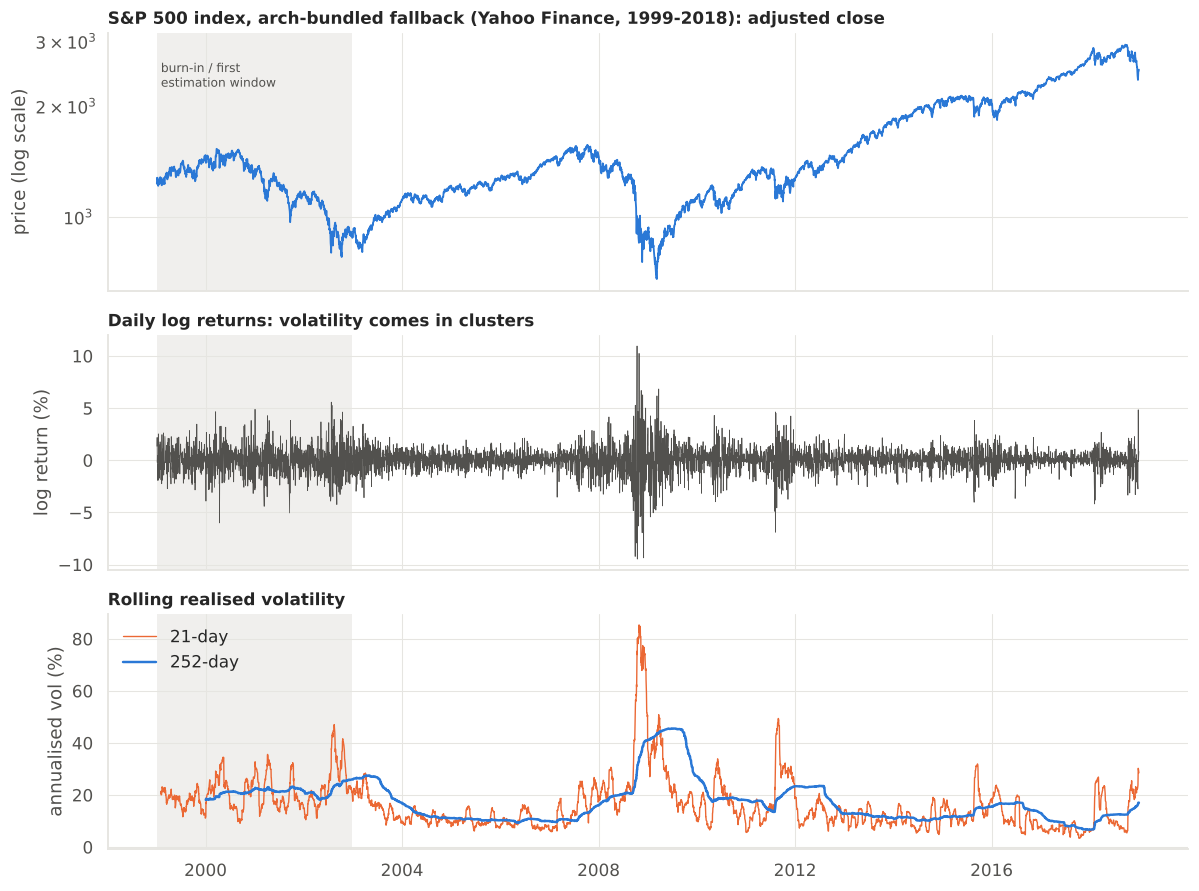

In [4]:
vol21 = returns.rolling(21).std() * np.sqrt(ANN)
vol252 = returns.rolling(252).std() * np.sqrt(ANN)

fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True, gridspec_kw={"height_ratios": [1.1, 1, 1]})
axes[0].plot(prices.index, prices, color=PAL["blue"])
axes[0].set_yscale("log"); axes[0].set_ylabel("price (log scale)")
axes[0].set_title(f"{DATA_LABEL}: adjusted close")
axes[1].plot(returns.index, 100 * returns, color=PAL["ink2"], lw=0.5)
axes[1].set_ylabel("log return (%)"); axes[1].set_title("Daily log returns: volatility comes in clusters")
axes[2].plot(vol21.index, 100 * vol21, color=PAL["orange"], lw=0.9, label="21-day")
axes[2].plot(vol252.index, 100 * vol252, color=PAL["blue"], lw=1.6, label="252-day")
axes[2].set_ylabel("annualised vol (%)"); axes[2].set_title("Rolling realised volatility"); axes[2].legend(loc="upper left")
for ax in axes:
    ax.axvspan(returns.index[0], oos_dates[0], color=PAL["grid"], alpha=0.6, lw=0)
axes[0].text(returns.index[20], prices.max() * 0.9, "burn-in / first\nestimation window", fontsize=8, color=PAL["ink2"], va="top")
fig.tight_layout(); plt.show()

### 3.3 Distributional properties

The Jarque–Bera statistic $JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right)$, with $S$ the sample skewness and $K$ the *excess* kurtosis, is asymptotically $\chi^2_2$ under normality. With thousands of daily observations it has power against even mild departures, so its p-value is expected to be essentially zero; the informative part is *how* the distribution departs from normal (sign of the skew, size of the kurtosis, where the empirical quantiles sit relative to the Gaussian ones).

In [5]:
def describe_returns(x: pd.Series) -> pd.DataFrame:
    """Summary statistics of daily log returns (decimal units unless stated)."""
    jb = stats.jarque_bera(x)
    q = x.quantile([0.001, 0.01, 0.05, 0.95, 0.99, 0.999])
    rows = {
        "observations": len(x),
        "mean (daily)": x.mean(), "mean (annualised)": x.mean() * ANN,
        "std (daily)": x.std(ddof=1), "volatility (annualised)": x.std(ddof=1) * np.sqrt(ANN),
        "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x, fisher=True),
        **{f"quantile {k:.1%}": v for k, v in q.items()},
        f"min ({x.idxmin().date()})": x.min(), f"max ({x.idxmax().date()})": x.max(),
        "Jarque-Bera statistic": jb.statistic, "Jarque-Bera p-value": jb.pvalue,
    }
    return pd.DataFrame({"value": rows})

desc = describe_returns(returns)
display(desc.map(lambda v: f"{v:.5g}"))

# Empirical tail frequencies vs the Gaussian with the same mean and variance
mu_full, sd_full = returns.mean(), returns.std(ddof=1)
tails = pd.DataFrame({
    "k (std devs)": [2, 3, 4, 5],
    "empirical P(r < mu - k sd)": [(returns < mu_full - k * sd_full).mean() for k in (2, 3, 4, 5)],
    "Gaussian P(Z < -k)": [stats.norm.cdf(-k) for k in (2, 3, 4, 5)],
})
tails["ratio empirical / Gaussian"] = tails.iloc[:, 1] / tails.iloc[:, 2]
display(tails.round(6))
log.info("Skewness %.3f, excess kurtosis %.2f, JB p-value %.3g", stats.skew(returns), stats.kurtosis(returns), stats.jarque_bera(returns).pvalue)

,value
observations,5030
mean (daily),0.00014186
mean (annualised),0.035749
std (daily),0.012038
volatility (annualised),0.1911
skewness,-0.20461
excess kurtosis,8.1692
quantile 0.1%,-0.068789
quantile 1.0%,-0.033618
quantile 5.0%,-0.018819


,k (std devs),empirical P(r < mu - k sd),Gaussian P(Z < -k),ratio empirical / Gaussian
0,2,0.028628,0.022750,1.258376
1,3,0.007753,0.001350,5.743752
2,4,0.003777,0.000032,119.267063
3,5,0.001590,0.000000,5548.398866


13:15:50 | INFO    | Skewness -0.205, excess kurtosis 8.17, JB p-value 0


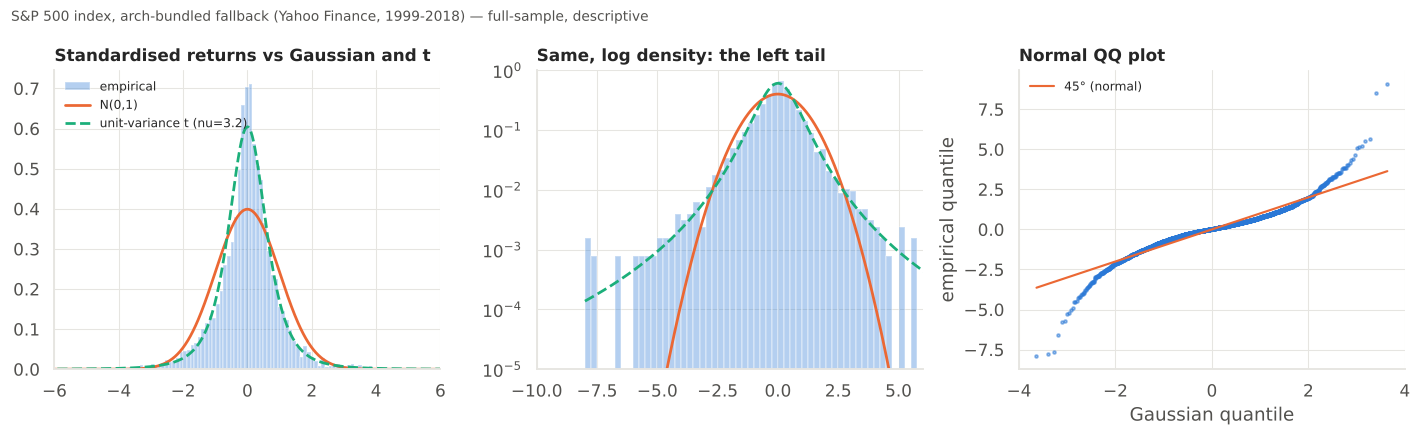

13:15:51 | INFO    | Full-sample unit-variance Student-t shape (descriptive only): nu = 3.19


In [6]:
z_full = (returns - mu_full) / sd_full
nu_full = optimize.minimize_scalar(
    lambda nu: -(stats.t.logpdf(z_full / np.sqrt((nu - 2) / nu), nu) - np.log(np.sqrt((nu - 2) / nu))).sum(),
    bounds=(2.05, 200), method="bounded").x

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
grid = np.linspace(-8, 8, 800)
axes[0].hist(z_full, bins=150, density=True, color=PAL["blue"], alpha=0.35, label="empirical")
axes[0].plot(grid, stats.norm.pdf(grid), color=PAL["orange"], lw=1.8, label="N(0,1)")
s = np.sqrt((nu_full - 2) / nu_full)
axes[0].plot(grid, stats.t.pdf(grid / s, nu_full) / s, color=PAL["aqua"], lw=1.8, ls="--", label=f"unit-variance t (nu={nu_full:.1f})")
axes[0].set_xlim(-6, 6); axes[0].set_title("Standardised returns vs Gaussian and t"); axes[0].legend(fontsize=8, loc="upper left")

axes[1].hist(z_full, bins=np.linspace(-10, 6, 65), density=True, color=PAL["blue"], alpha=0.35)
axes[1].plot(grid, stats.norm.pdf(grid), color=PAL["orange"], lw=1.8)
axes[1].plot(grid, stats.t.pdf(grid / s, nu_full) / s, color=PAL["aqua"], lw=1.8, ls="--")
axes[1].set_yscale("log"); axes[1].set_ylim(1e-5, 1); axes[1].set_xlim(-10, 6)
axes[1].set_title("Same, log density: the left tail")

(osm, osr), (slope, icpt, _) = stats.probplot(z_full, dist="norm")
axes[2].scatter(osm, osr, s=4, color=PAL["blue"], alpha=0.5)
axes[2].plot(osm, osm, color=PAL["orange"], lw=1.4, label="45° (normal)")
axes[2].set_xlabel("Gaussian quantile"); axes[2].set_ylabel("empirical quantile")
axes[2].set_title("Normal QQ plot"); axes[2].legend(fontsize=8)
fig.suptitle(f"{DATA_LABEL} — full-sample, descriptive", x=0.01, ha="left", fontsize=9, color=PAL["ink2"])
fig.tight_layout(); plt.show()
log.info("Full-sample unit-variance Student-t shape (descriptive only): nu = %.2f", nu_full)

### 3.4 Volatility clustering

Returns are close to serially uncorrelated (weak-form efficiency), but **squared and absolute returns are strongly and persistently autocorrelated**: large moves follow large moves. The Ljung–Box statistic $Q(m) = n(n+2)\sum_{k=1}^m \hat\rho_k^2/(n-k)$ is asymptotically $\chi^2_m$ under no autocorrelation up to lag $m$.

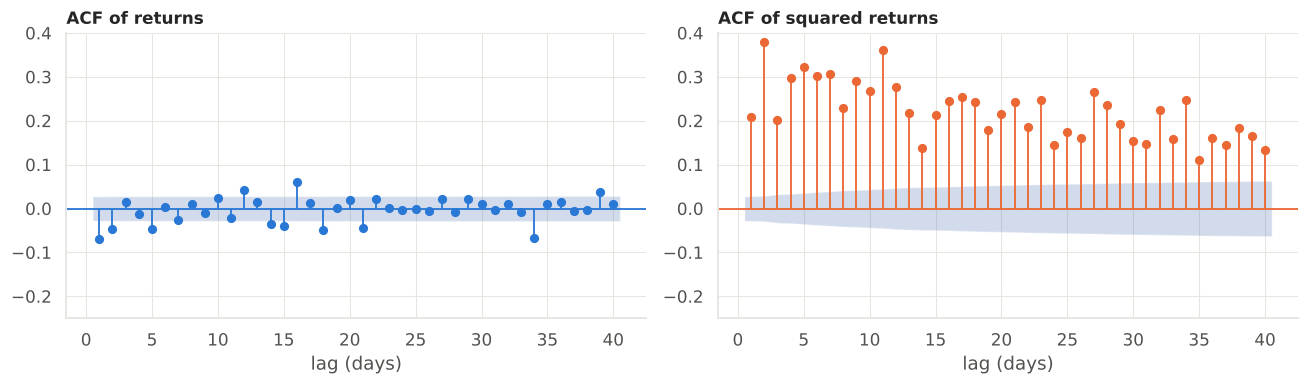

returns           squared returns          
     lb_stat lb_pvalue         lb_stat lb_pvalue
5    48.2610       0.0       2110.3195       0.0
10   55.9109       0.0       4086.4598       0.0
20  116.1892       0.0       7028.4653       0.0

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(returns, lags=40, ax=axes[0], zero=False, color=PAL["blue"], vlines_kwargs={"colors": PAL["blue"]})
axes[0].set_title("ACF of returns"); axes[0].set_ylim(-0.25, 0.4)
plot_acf(returns ** 2, lags=40, ax=axes[1], zero=False, color=PAL["orange"], vlines_kwargs={"colors": PAL["orange"]})
axes[1].set_title("ACF of squared returns"); axes[1].set_ylim(-0.25, 0.4)
for ax in axes:
    ax.set_xlabel("lag (days)")
fig.tight_layout(); plt.show()

lb = pd.concat({"returns": acorr_ljungbox(returns, lags=[5, 10, 20]),
                "squared returns": acorr_ljungbox(returns ** 2, lags=[5, 10, 20])}, axis=1)
display(lb.round(4))

### 3.5 Interpretation

* **Fat tails.** Excess kurtosis far above zero and multi-sigma moves occurring many times more often than a Gaussian with the same variance allows (table above). A Gaussian calibrated on the full-sample variance understates the frequency of extreme losses, and the understatement grows with the confidence level.
* **Asymmetry.** Equity index returns are negatively skewed: the largest moves are losses, and losses tend to come in clusters. A symmetric distribution, even a fat-tailed one, cannot represent this.
* **Volatility clustering.** Returns themselves are barely autocorrelated, while squared returns are autocorrelated for dozens of lags (Ljung–Box p-values ≈ 0). The *conditional* distribution of tomorrow's return depends strongly on recent volatility.
* **Consequence for VaR.** Much of the unconditional kurtosis comes from mixing calm and turbulent periods. A model that ignores the current volatility state (historical simulation, unconditional Gaussian/t) produces VaR that is *too high in calm periods and too low in crises*, and its violations will cluster precisely when risk matters. This is the hypothesis the backtest of Sections 8–9 tests formally.

## 4. Historical VaR and Expected Shortfall

### 4.1 Estimator

Let $r_{(1)} \le \dots \le r_{(n)}$ be the order statistics of the $n$ returns in the window and $k = \lceil np \rceil$. Historical simulation uses the empirical distribution of the window as the forecast distribution of tomorrow's return:

$$\widehat{\mathrm{VaR}}_\alpha = -r_{(k)}, \qquad \widehat{\mathrm{ES}}_\alpha = -\frac{1}{np}\Big[\sum_{i=1}^{k-1} r_{(i)} + (np - k + 1)\, r_{(k)}\Big].$$

* The VaR is the **left-continuous empirical quantile** $\inf\{x : \hat F_n(x) \ge p\}$ — an *observed* return, no interpolation (NumPy's `method="inverted_cdf"`, Hyndman–Fan type 1).
* The ES is the **exact tail mean of the empirical distribution** (Acerbi & Tasche, 2002): it averages exactly a fraction $p$ of probability mass, giving fractional weight to $r_{(k)}$ when $np$ is not an integer. Ties are handled correctly because the formula works on order statistics. The naïve "average of returns below the VaR" is not coherent for discrete distributions and is sensitive to ties.
* Example: $n=250$, $p=1\%$ gives $np = 2.5$, so $\mathrm{VaR} = -r_{(3)}$ and $\mathrm{ES} = -(r_{(1)} + r_{(2)} + 0.5\,r_{(3)})/2.5$. **The whole 99% tail of a one-year window rests on three observations.**

In [8]:
def empirical_var_es(x, alpha: float):
    """Empirical VaR and ES (positive losses) of returns along the LAST axis of `x`.

    VaR = -x_(k) with k = ceil(n p); ES = exact tail mean of the empirical distribution (Acerbi-Tasche).
    Works on a 1-D sample or a 2-D array of windows (one window per row).
    """
    x = np.asarray(x, dtype=float)
    if not np.isfinite(x).all():
        raise ValueError("empirical_var_es: non-finite input")
    p = tail_prob(alpha)
    n = x.shape[-1]
    n_p = n * p
    k = int(np.ceil(round(n_p, 9)))                  # rounding guards against 500 * 0.05 = 25.000000000000004
    if k < 1 or k >= n:
        raise ValueError(f"window of {n} too short for alpha={alpha}")
    xs = np.sort(x, axis=-1)
    q = xs[..., k - 1]
    tail_sum = xs[..., : k - 1].sum(axis=-1) + (n_p - (k - 1)) * q
    return -q, -tail_sum / n_p


def window_matrix(x: np.ndarray, targets: np.ndarray, window: int) -> np.ndarray:
    """Row i = x[targets[i]-window : targets[i]], i.e. the `window` observations BEFORE target day i."""
    if targets.min() - window < 0:
        raise ValueError("window starts before the sample")
    return sliding_window_view(x, window)[targets - window]


# --- illustration on the first forecast date T0 (estimation data end at T0-1) ---
rows = []
for w in W_HS_GRID:
    for a in ALPHAS:
        v, e = empirical_var_es(r[T0 - w:T0], a)
        rows.append({"window": w, "alpha": a, "tail obs (n p)": w * tail_prob(a), "VaR": pct(v), "ES": pct(e)})
display(pd.DataFrame(rows).set_index(["window", "alpha"]))

# --- quantile conventions on a 250-day window at 99 % -------------------------
x250 = r[T0 - 250:T0]
methods = ["inverted_cdf", "lower", "linear", "hazen", "median_unbiased", "higher"]
conv = pd.Series({m: -np.quantile(x250, tail_prob(0.99), method=m) for m in methods}, name="VaR 99%")
assert np.isclose(conv["inverted_cdf"], empirical_var_es(x250, 0.99)[0]), "estimator must equal NumPy inverted_cdf"
display(conv.map(pct).to_frame())
log.info("On 250 obs the 99%% VaR ranges from %s to %s across quantile conventions",
         pct(conv.min()), pct(conv.max()))

tail obs (n p)    VaR     ES
window alpha                              
250    0.95             12.5  2.51%  3.21%
       0.99              2.5  3.49%  3.96%
500    0.95             25.0  2.47%  3.13%
       0.99              5.0  3.50%  4.22%
1000   0.95             50.0  2.26%  2.92%
       0.99             10.0  3.35%  4.13%

,VaR 99%
inverted_cdf,3.49%
lower,3.49%
linear,3.47%
hazen,3.49%
median_unbiased,3.56%
higher,3.46%


13:15:51 | INFO    | On 250 obs the 99% VaR ranges from 3.46% to 3.56% across quantile conventions


With 250 observations the 99% quantile sits between the 2nd and 3rd smallest returns, so the choice of quantile convention alone moves the 99% VaR visibly (table above). This is estimation noise that no backtest at a 250-day horizon can detect. The notebook uses `inverted_cdf` throughout because it is the standard empirical quantile, returns an actually observed loss and is consistent with the ES formula.

### 4.2 Rolling historical VaR and window-length sensitivity

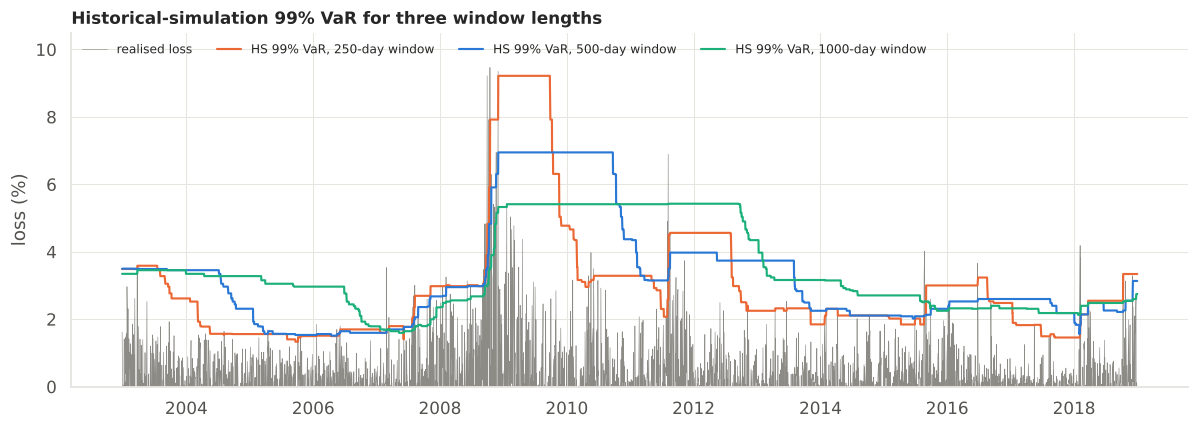

avg VaR avg ES  violations  expected violation rate VaR std (time series)
window alpha                                                                          
250    0.95    1.77%  2.42%         210     201.5          5.21%                 0.97%
       0.99    2.97%  3.39%          55      40.3          1.36%                 1.80%
500    0.95    1.80%  2.60%         209     201.5          5.19%                 0.76%
       0.99    3.20%  3.86%          56      40.3          1.39%                 1.57%
1000   0.95    1.91%  2.81%         196     201.5          4.86%                 0.57%
       0.99    3.40%  4.38%          58      40.3          1.44%                 1.24%

In [9]:
hs_by_window = {}
for w in W_HS_GRID:
    for a in ALPHAS:
        hs_by_window[(w, a)] = empirical_var_es(window_matrix(r, OOS_IDX, w), a)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(oos_dates, 100 * L_oos, color=PAL["muted"], lw=0.4, label="realised loss")
for w, c in zip(W_HS_GRID, (PAL["orange"], PAL["blue"], PAL["aqua"])):
    ax.plot(oos_dates, 100 * hs_by_window[(w, 0.99)][0], color=c, lw=1.4, label=f"HS 99% VaR, {w}-day window")
ax.set_ylim(bottom=0); ax.set_ylabel("loss (%)"); ax.legend(loc="upper left", ncol=4, fontsize=8)
ax.set_title("Historical-simulation 99% VaR for three window lengths")
fig.tight_layout(); plt.show()

rows = []
for (w, a), (v, e) in hs_by_window.items():
    hits = L_oos > v
    rows.append({"window": w, "alpha": a, "avg VaR": pct(v.mean()), "avg ES": pct(e.mean()),
                 "violations": int(hits.sum()), "expected": round(len(hits) * tail_prob(a), 1),
                 "violation rate": pct(hits.mean()), "VaR std (time series)": pct(v.std())})
display(pd.DataFrame(rows).set_index(["window", "alpha"]))

**Reading the sensitivity analysis.** Short windows track the volatility regime faster but are noisy at 99% (two or three tail points) and jump when a large loss enters *or leaves* the window — the characteristic "plateau and cliff" pattern exactly 250 days after a crash, a pure artefact of the method. Long windows are smoother but keep stale crisis data for years and adapt slowly to new crises. The formal tests in Section 8 use the 500-day HS as the benchmark.

**Limitations of historical simulation.**

1. **Implicit i.i.d. assumption:** every past day is equally likely tomorrow, whatever today's volatility. HS therefore cannot react to a volatility spike until enough large losses have *entered* the window.
2. **Few tail observations:** the 99% ES of a 500-day window averages five numbers; its sampling error is large.
3. **Bounded support:** HS can never forecast a loss larger than the worst loss in the window.
4. **Sample dependence:** results depend on which crises the window happens to contain.

## 5. Parametric VaR: Gaussian and Student-t

### 5.1 Location–scale framework

Write $r_t = \mu_t + \sigma_t z_t$ with $z_t$ i.i.d., $\mathbb E z_t = 0$, $\operatorname{Var} z_t = 1$, cdf $F_z$. Because VaR and ES are translation-equivariant and positively homogeneous,

$$\mathrm{VaR}_{\alpha,t} = -\big(\mu_t + \sigma_t\, q_z(p)\big), \qquad \mathrm{ES}_{\alpha,t} = -\mu_t + \sigma_t\,\mathrm{ES}_z(p), \qquad \mathrm{ES}_z(p) = -\mathbb E[z \mid z \le q_z(p)] > 0.$$

In this section $\mu_t$ and $\sigma_t$ are the sample mean and standard deviation of the trailing `W_UNC`-day window (unconditional models). In Section 7 they become GARCH forecasts.

**Gaussian.** $q_z(p) = \Phi^{-1}(p)$ and $\mathrm{ES}_z(p) = \varphi(\Phi^{-1}(p))/p$.

### 5.2 Student-t: standard vs variance-standardised

The *standard* Student-t $T \sim t_\nu$ has variance $\nu/(\nu-2) > 1$. Using its quantile with $\sigma_t$ = the standard deviation of returns double-counts tail thickness. The **variance-standardised** t is

$$z = \sqrt{\tfrac{\nu-2}{\nu}}\;T, \qquad \operatorname{Var}(z) = 1 \quad (\nu > 2),$$

so with $s_\nu = \sqrt{(\nu-2)/\nu}$:

$$q_z(p) = s_\nu\, t_\nu^{-1}(p), \qquad \mathrm{ES}_z(p) = s_\nu\,\frac{f_\nu\big(t_\nu^{-1}(p)\big)}{p}\cdot\frac{\nu + \big(t_\nu^{-1}(p)\big)^2}{\nu - 1},$$

where $f_\nu$ is the standard $t_\nu$ density (the ES expression is the closed-form tail mean of $t_\nu$, which requires $\nu > 1$). This is also the parameterisation of `arch`'s `StudentsT` distribution, so Sections 5, 6 and 7 share one set of formulas.

**Estimation.** $\hat\mu, \hat\sigma$ are the window's sample moments; $\nu$ is estimated by maximum likelihood of the unit-variance t on the standardised window $(r - \hat\mu)/\hat\sigma$ (two-step estimator; $\hat\sigma$ is consistent for $\nu > 2$ but not efficient), bounded in $[2.05, 200]$, and re-estimated every `REFIT_EVERY` days.

In [10]:
def var_es_normal(mu, sigma, alpha):
    """Gaussian VaR and ES (positive losses) for r = mu + sigma * z, z ~ N(0,1)."""
    p = tail_prob(alpha)
    zq = stats.norm.ppf(p)
    return -(mu + sigma * zq), -mu + sigma * stats.norm.pdf(zq) / p


def std_t_scale(nu):
    nu = np.asarray(nu, dtype=float)
    if np.any(nu <= 2):
        raise ValueError("unit-variance Student-t requires nu > 2")
    return np.sqrt((nu - 2.0) / nu)


def std_t_ppf(p, nu):
    """Quantile of the unit-variance Student-t."""
    return stats.t.ppf(p, nu) * std_t_scale(nu)


def std_t_es(p, nu):
    """ES_z(p) = -E[z | z <= q_z(p)] (> 0) of the unit-variance Student-t."""
    q = stats.t.ppf(p, nu)
    return std_t_scale(nu) * stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1.0)


def var_es_std_t(mu, sigma, alpha, nu):
    """Student-t VaR and ES (positive losses) for r = mu + sigma * z, z ~ unit-variance t_nu."""
    p = tail_prob(alpha)
    return -(mu + sigma * std_t_ppf(p, nu)), -mu + sigma * std_t_es(p, nu)


def std_t_logpdf(z, nu):
    s = std_t_scale(nu)
    return stats.t.logpdf(z / s, nu) - np.log(s)


def fit_std_t_nu(z, bounds=(2.05, 200.0)) -> float:
    """MLE of nu for already-standardised data z (unit-variance parameterisation)."""
    res = optimize.minimize_scalar(lambda nu: -std_t_logpdf(z, nu).sum(), bounds=bounds,
                                   method="bounded", options={"xatol": 1e-4})
    if not res.success:
        raise RuntimeError(f"nu estimation failed: {res.message}")
    return float(res.x)


# ---------------------------------------- correctness checks against numerical integration
checks = []
for nu_ in (3.0, 4.5, 8.0, 30.0):
    s_ = float(std_t_scale(nu_))
    pdf_z = lambda z, nu_=nu_, s_=s_: stats.t.pdf(z / s_, nu_) / s_
    var_num = integrate.quad(lambda z: z * z * pdf_z(z), -np.inf, np.inf)[0]
    for a in ALPHAS:
        p = tail_prob(a)
        q = float(std_t_ppf(p, nu_))
        cdf_at_q = integrate.quad(pdf_z, -np.inf, q)[0]
        es_num = -integrate.quad(lambda z: z * pdf_z(z), -np.inf, q)[0] / p
        checks.append({"nu": nu_, "alpha": a, "variance (num.)": var_num, "F(q) - p": cdf_at_q - p,
                       "ES closed form": float(std_t_es(p, nu_)), "ES numerical": es_num})
chk = pd.DataFrame(checks)
assert np.allclose(chk["variance (num.)"], 1, atol=1e-6), "unit-variance t does not have unit variance"
assert np.allclose(chk["F(q) - p"], 0, atol=1e-8), "unit-variance t quantile is wrong"
assert np.allclose(chk["ES closed form"], chk["ES numerical"], rtol=1e-6), "Student-t ES formula is wrong"
for a in ALPHAS:
    p = tail_prob(a)
    es_num = -integrate.quad(lambda z: z * stats.norm.pdf(z), -np.inf, stats.norm.ppf(p))[0] / p
    assert np.isclose(var_es_normal(0, 1, a)[1], es_num, rtol=1e-8), "Gaussian ES formula is wrong"
log.info("Checks passed: unit variance, quantile and ES of the standardised t; Gaussian ES (numerical integration)")
display(chk.round(8))

13:15:52 | INFO    | Checks passed: unit variance, quantile and ES of the standardised t; Gaussian ES (numerical integration)


,nu,alpha,variance (num.),F(q) - p,ES closed form,ES numerical
0,3.0,0.95,1.0,-0.0,2.236809,2.236809
1,3.0,0.99,1.0,-0.0,4.043231,4.043231
2,4.5,0.95,1.0,0.0,2.252558,2.252558
3,4.5,0.99,1.0,0.0,3.556301,3.556301
4,8.0,0.95,1.0,0.0,2.177060,2.177060
5,8.0,0.99,1.0,-0.0,3.109802,3.109802
6,30.0,0.95,1.0,0.0,2.092557,2.092557
7,30.0,0.99,1.0,-0.0,2.768459,2.768459


### 5.3 How tail thickness moves VaR and ES

Holding the variance fixed, a smaller $\nu$ moves probability mass both to the centre and to the far tails, and *away from the shoulders*. As a result the unit-variance t quantile is **smaller** in absolute value than the Gaussian one at moderate confidence levels and **larger** only beyond a crossover level that depends on $\nu$. ES, which integrates the whole tail, is affected more strongly than VaR.

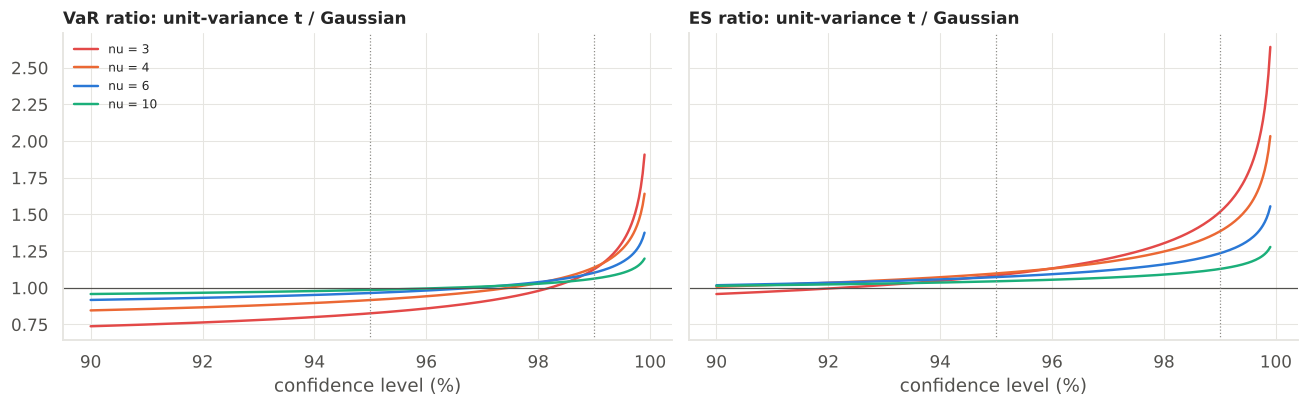

13:15:53 | INFO    | Window ending 2002-12-26: mu=-0.00078, sigma=0.01503, nu=7.37


VaR      ES  ES / VaR
alpha model                                        
0.95  Historical           2.473%  3.127%     1.264
      Gaussian             2.550%  3.178%     1.246
      Student-t (nu=7.37)  2.490%  3.364%     1.351
0.99  Historical           3.500%  4.223%     1.207
      Gaussian             3.574%  4.084%     1.142
      Student-t (nu=7.37)  3.871%  4.820%     1.245

In [11]:
alpha_grid = np.linspace(0.90, 0.999, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for nu_, c in zip((3, 4, 6, 10), (PAL["red"], PAL["orange"], PAL["blue"], PAL["aqua"])):
    v_ratio = [var_es_std_t(0, 1, a, nu_)[0] / var_es_normal(0, 1, a)[0] for a in alpha_grid]
    e_ratio = [var_es_std_t(0, 1, a, nu_)[1] / var_es_normal(0, 1, a)[1] for a in alpha_grid]
    axes[0].plot(100 * alpha_grid, v_ratio, color=c, lw=1.6, label=f"nu = {nu_}")
    axes[1].plot(100 * alpha_grid, e_ratio, color=c, lw=1.6, label=f"nu = {nu_}")
for ax, ttl in zip(axes, ("VaR ratio: unit-variance t / Gaussian", "ES ratio: unit-variance t / Gaussian")):
    ax.axhline(1, color=PAL["ink2"], lw=0.8)
    for a in ALPHAS:
        ax.axvline(100 * a, color=PAL["muted"], lw=0.8, ls=":")
    ax.set_xlabel("confidence level (%)"); ax.set_title(ttl)
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

# --------------------------- comparison on the first forecast date (window ends at T0-1)
w_x = r[T0 - W_UNC:T0]
mu0, sd0 = w_x.mean(), w_x.std(ddof=1)
nu0 = fit_std_t_nu((w_x - mu0) / sd0)
rows = []
for a in ALPHAS:
    for name, (v, e) in {"Historical": empirical_var_es(w_x, a), "Gaussian": var_es_normal(mu0, sd0, a),
                         f"Student-t (nu={nu0:.2f})": var_es_std_t(mu0, sd0, a, nu0)}.items():
        rows.append({"alpha": a, "model": name, "VaR": pct(v, 3), "ES": pct(e, 3), "ES / VaR": round(e / v, 3)})
log.info("Window ending %s: mu=%.5f, sigma=%.5f, nu=%.2f", returns.index[T0 - 1].date(), mu0, sd0, nu0)
display(pd.DataFrame(rows).set_index(["alpha", "model"]))

**Distributional misspecification.** The Gaussian model fits the variance but not the shape: it typically overstates the 95% VaR (fat-tailed data have *thin shoulders*) and understates the 99% VaR and, above all, the ES. The ES/VaR ratio is a useful diagnostic: about 1.25 at 95% and 1.15 at 99% for any Gaussian, but larger for heavy tails. The Student-t corrects the tail thickness but remains **symmetric** and **unconditional**: it cannot reproduce the negative skew of equity returns, and its $\sigma$ is a 500-day average, blind to the current volatility regime. The calibration differences between Gaussian and t are second order compared with that conditioning problem (Sections 8–9).

## 6. Monte Carlo Simulation

### 6.1 Engine

For a one-day horizon we simulate $N$ i.i.d. draws $r^{(i)} = \hat\mu + \hat\sigma z^{(i)}$, with $z^{(i)} \sim \mathcal N(0,1)$ or unit-variance $t_\nu$ (generated as $s_\nu T^{(i)}$, $T^{(i)} \sim t_\nu$), and apply the empirical estimator of Section 4 to the simulated sample. This is **one-day** VaR: no multi-day path is simulated, and no square-root-of-time scaling is involved.

**Monte Carlo error.** For the empirical quantile of $N$ draws, $\sqrt N(\hat q - q) \xrightarrow{d} \mathcal N\!\big(0,\; p(1-p)/f_r(q)^2\big)$, so the standard error of the simulated VaR is $\sqrt{p(1-p)/N}\,/\,f_r(q)$, with $f_r(q) = f_z(q_z)/\sigma$. The error shrinks like $N^{-1/2}$ and is larger at 99% than at 95% because the density is thinner further out in the tail.

> **Monte Carlo does not improve a risk model.** It is a numerical integration device: it converges to the VaR *of the assumed return-generating process*. When a closed form exists (as here) it adds only noise. Its value lies in cases with no closed form (non-linear portfolios, many risk factors, path dependence, multi-day horizons with dynamics), and its answer is only as good as the model it simulates.

In [12]:
def simulate_innovations(dist: str, n: int, rng: np.random.Generator, nu: float | None = None) -> np.ndarray:
    """Zero-mean, unit-variance innovations."""
    if n < 1:
        raise ValueError("n must be positive")
    if dist == "normal":
        return rng.standard_normal(n)
    if dist == "t":
        if nu is None or nu <= 2:
            raise ValueError("Student-t simulation needs nu > 2")
        return rng.standard_t(nu, n) * float(std_t_scale(nu))
    raise ValueError(f"unknown distribution {dist!r}")


def mc_var_es(mu, sigma, alpha, n_sims, dist, rng, nu=None):
    """One-day Monte Carlo VaR and ES (positive losses)."""
    if n_sims * tail_prob(alpha) < 20:
        log.warning("only %.0f simulated tail draws at alpha=%s: very noisy", n_sims * tail_prob(alpha), alpha)
    return empirical_var_es(mu + sigma * simulate_innovations(dist, n_sims, rng, nu), alpha)


rng_mc = np.random.default_rng(SEED)
analytic = {("normal", a): var_es_normal(mu0, sd0, a) for a in ALPHAS}
analytic |= {("t", a): var_es_std_t(mu0, sd0, a, nu0) for a in ALPHAS}

rows = []
t_start = time.perf_counter()
for dist in ("normal", "t"):
    nu_arg = nu0 if dist == "t" else None
    for a in ALPHAS:
        p = tail_prob(a)
        v_true, e_true = analytic[(dist, a)]
        zq = stats.norm.ppf(p) if dist == "normal" else float(std_t_ppf(p, nu0))
        f_z = stats.norm.pdf(zq) if dist == "normal" else float(np.exp(std_t_logpdf(zq, nu0)))
        for n in MC_GRID:
            v1, e1 = mc_var_es(mu0, sd0, a, n, dist, rng_mc, nu_arg)            # one seeded run
            reps = np.array([mc_var_es(mu0, sd0, a, n, dist, rng_mc, nu_arg) for _ in range(N_MC_REPS)])
            rows.append({"innovations": dist, "alpha": a, "N": n,
                         "analytic VaR": v_true, "MC VaR": v1, "VaR rel. error": v1 / v_true - 1,
                         "VaR SE (replications)": reps[:, 0].std(ddof=1),
                         "VaR SE (asymptotic)": np.sqrt(p * (1 - p) / n) / (f_z / sd0),
                         "analytic ES": e_true, "MC ES": e1, "ES rel. error": e1 / e_true - 1,
                         "ES SE (replications)": reps[:, 1].std(ddof=1)})
mc_tbl = pd.DataFrame(rows).set_index(["innovations", "alpha", "N"])
log.info("Monte Carlo experiment: %d configurations x %d replications in %.1fs",
         len(rows), N_MC_REPS, time.perf_counter() - t_start)
fmt = mc_tbl.copy()
for c in fmt.columns:
    fmt[c] = fmt[c].map(lambda v: f"{100 * v:+.3f}%" if "rel." in c else f"{100 * v:.4f}%")
display(fmt)

13:15:58 | INFO    | Monte Carlo experiment: 12 configurations x 200 replications in 4.4s


analytic VaR   MC VaR VaR rel. error VaR SE (replications) VaR SE (asymptotic) analytic ES    MC ES ES rel. error ES SE (replications)
innovations alpha N                                                                                                                                            
normal      0.95  10000       2.5501%  2.5907%        +1.592%               0.0313%             0.0318%     3.1781%  3.2487%       +2.222%              0.0385%
                  50000       2.5501%  2.5563%        +0.243%               0.0142%             0.0142%     3.1781%  3.1592%       -0.594%              0.0165%
                  100000      2.5501%  2.5465%        -0.142%               0.0101%             0.0100%     3.1781%  3.1818%       +0.117%              0.0116%
            0.99  10000       3.5743%  3.5607%        -0.382%               0.0508%             0.0561%     4.0836%  4.1342%       +1.240%              0.0649%
                  50000       3.5743%  3.5886%        +0.399%               0.0250%             0.0251%     4.0836%  4.0928%       +0.227%              0.0314%
                  100000      3.5743%  3.5624%        -0.332%               0.0178%             0.0177%     4.0836%  4.0959%       +0.301%              0.0221%
t           0.95  10000       2.4903%  2.4599%        -1.221%               0.0344%             0.0374%     3.3645%  3.3137%       -1.509%              0.0570%
                  50000       2.4903%  2.5137%        +0.940%               0.0163%             0.0167%     3.3645%  3.3658%       +0.040%              0.0238%
                  100000      2.4903%  2.4846%        -0.227%               0.0118%             0.0118%     3.3645%  3.3904%       +0.770%              0.0181%
            0.99  10000       3.8710%  3.9061%        +0.907%               0.0885%             0.0874%     4.8203%  4.8673%       +0.975%              0.1340%
                  50000       3.8710%  3.7909%        -2.068%               0.0380%             0.0391%     4.8203%  4.7159%       -2.165%              0.0623%
                  100000      3.8710%  3.8649%        -0.157%               0.0273%             0.0276%     4.8203%  4.8621%       +0.867%              0.0407%

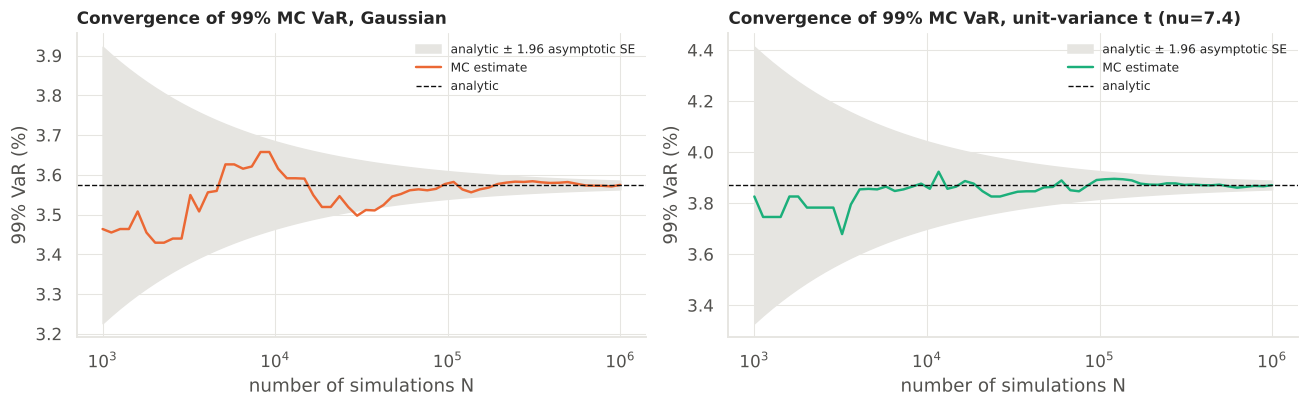

In [13]:
# Convergence of the 99 % VaR along a single stream of draws
rng_conv = np.random.default_rng(SEED + 1)
N_MAX = 1_000_000
n_path = np.unique(np.logspace(3, np.log10(N_MAX), 60).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, dist, c in zip(axes, ("normal", "t"), (PAL["orange"], PAL["aqua"])):
    nu_arg = nu0 if dist == "t" else None
    draws = mu0 + sd0 * simulate_innovations(dist, N_MAX, rng_conv, nu_arg)
    est = np.array([empirical_var_es(draws[:n], 0.99)[0] for n in n_path])
    v_true = analytic[(dist, 0.99)][0]
    zq = stats.norm.ppf(0.01) if dist == "normal" else float(std_t_ppf(0.01, nu0))
    f_r = (stats.norm.pdf(zq) if dist == "normal" else float(np.exp(std_t_logpdf(zq, nu0)))) / sd0
    band = 1.96 * np.sqrt(0.01 * 0.99 / n_path) / f_r
    ax.fill_between(n_path, 100 * (v_true - band), 100 * (v_true + band), color=PAL["grid"], label="analytic ± 1.96 asymptotic SE")
    ax.plot(n_path, 100 * est, color=c, lw=1.6, label="MC estimate")
    ax.axhline(100 * v_true, color=PAL["ink"], lw=0.9, ls="--", label="analytic")
    ax.set_xscale("log"); ax.set_xlabel("number of simulations N"); ax.set_ylabel("99% VaR (%)")
    ax.set_title(f"Convergence of 99% MC VaR, {'Gaussian' if dist == 'normal' else f'unit-variance t (nu={nu0:.1f})'}")
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Reading the Monte Carlo results.** The replication standard errors match the asymptotic formula closely, confirming the engine and the $N^{-1/2}$ rate. At $N = 10{,}000$ the 99% VaR still carries a relative standard error of 1–2%; the Student-t case is noisier than the Gaussian because its density at the 1% quantile is lower. The ES is estimated from only $Np$ tail draws and is noisier than the VaR in relative terms. Most importantly, the simulated numbers converge to the **analytical** VaR of the same model: simulation inherits every assumption of that model (i.i.d., unconditional $\sigma$, symmetric tails). In the backtest, *MC Student-t* is the Student-t model plus simulation noise, which is exactly what its results should show.

## 7. GARCH and EGARCH Models

### 7.1 Specifications

Returns are modelled in **percent** ($y_t = 100\,r_t$) for numerical stability of the optimiser. VaR and ES are converted back to decimal log-return units before any comparison. All four models share a **constant conditional mean**:

$$y_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \overset{iid}{\sim} \mathcal N(0,1) \text{ or unit-variance } t_\nu.$$

At a one-day horizon the drift is two orders of magnitude smaller than $\sigma_t$, so a constant mean is a harmless simplification. It is still estimated rather than set to zero, which keeps the mean equation consistent with the residuals used in Section 10.

**GARCH(1,1)** (Bollerslev, 1986):
$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2, \qquad \omega > 0,\ \alpha, \beta \ge 0,\ \alpha + \beta < 1.$$
Persistence $\alpha+\beta$, unconditional variance $\omega/(1-\alpha-\beta)$, half-life of a variance shock $\ln 0.5 / \ln(\alpha+\beta)$ days. The response is **symmetric** in the sign of $\varepsilon_{t-1}$.

**EGARCH(1,1)** (Nelson, 1991; `arch` parameterisation with one asymmetric term):
$$\ln\sigma_t^2 = \omega + \alpha\big(|z_{t-1}| - \sqrt{2/\pi}\big) + \gamma\, z_{t-1} + \beta \ln\sigma_{t-1}^2.$$
No positivity constraints are needed (the log keeps $\sigma_t^2 > 0$). $\gamma < 0$ captures the **leverage effect**: negative returns raise volatility more than positive returns of the same size. Stationarity requires $|\beta| < 1$. ($\sqrt{2/\pi} = \mathbb E|z|$ under normality; under a t-distribution the centring term is not exact, which only shifts $\omega$.)

**Estimation:** maximum likelihood (Gaussian likelihood = QMLE, consistent for the volatility parameters even if $z$ is not Gaussian; Student-t likelihood estimates $\nu$ jointly).

### 7.2 One-day-ahead VaR and ES

Given $\hat\mu$ and the forecast $\hat\sigma_{t}$ (both from information at $t-1$), the forecast distribution of $r_t$ is location–scale, so the formulas of Section 5 apply directly with the model's own innovation distribution:

$$\mathrm{VaR}_{\alpha,t} = -\frac{\hat\mu + \hat\sigma_t\, q_z(p)}{100}, \qquad \mathrm{ES}_{\alpha,t} = \frac{-\hat\mu + \hat\sigma_t\,\mathrm{ES}_z(p)}{100}.$$

### 7.3 Illustrative in-sample fit (first estimation window)

The fits below use **only** the 1,000 returns before the first forecast date: they are the models that produce the very first out-of-sample forecast. Everything in this subsection is *in-sample*.

In [14]:
GARCH_SPECS = {
    "GARCH-N":  dict(vol="GARCH",  o=0, dist="normal"),
    "GARCH-t":  dict(vol="GARCH",  o=0, dist="t"),
    "EGARCH-N": dict(vol="EGARCH", o=1, dist="normal"),
    "EGARCH-t": dict(vol="EGARCH", o=1, dist="t"),
}

def make_model(y: pd.Series, spec: dict):
    return arch_model(y, mean="Constant", vol=spec["vol"], p=1, o=spec["o"], q=1, dist=spec["dist"], rescale=False)

def admissibility_issue(params: pd.Series, spec: dict) -> str | None:
    """Reasons to reject a numerically 'converged' estimate (None = admissible).

    The optimiser can report success at degenerate local optima (|mu| of several percent per day, nu stuck
    at its lower bound, EGARCH with a negative size effect). Those estimates are rejected here.
    """
    if not np.isfinite(params.to_numpy()).all():
        return "non-finite parameters"
    if abs(params["mu"]) > 1.0:
        return f"implausible mean {params['mu']:.3g}%/day"
    if spec["vol"] == "GARCH":
        if params["omega"] <= 0 or params["alpha[1]"] < 0 or params["beta[1]"] < 0:
            return "negative variance parameters"
        if params["alpha[1]"] + params["beta[1]"] > 1.0 + 1e-8:
            return f"explosive: alpha+beta={params['alpha[1]'] + params['beta[1]']:.6f}"
    else:
        if not 0.0 < params["beta[1]"] < 1.0:
            return f"beta outside (0,1): {params['beta[1]']:.4f}"
        if not 0.0 < params["alpha[1]"] < 1.0:
            return f"size effect alpha outside (0,1): {params['alpha[1]']:.4f} (filter not invertible)"
        if abs(params["gamma[1]"]) > 1.0:
            return f"implausible leverage gamma {params['gamma[1]']:.3f}"
    if "nu" in params.index and params["nu"] < 2.1:
        return f"nu at lower bound ({params['nu']:.3f})"
    return None


def persistence(params: pd.Series, spec: dict) -> float:
    return float(params["alpha[1]"] + params["beta[1]"]) if spec["vol"] == "GARCH" else float(params["beta[1]"])


def _backcast(e: np.ndarray) -> float:
    """arch's default variance initialisation: EWMA (lambda 0.94) of the first 75 squared residuals."""
    tau = min(75, len(e))
    w = 0.94 ** np.arange(tau)
    return float(np.sum(e[:tau] ** 2 * w / w.sum()))


def filter_volatility(y: np.ndarray, params: pd.Series, spec: dict) -> np.ndarray:
    """Causal volatility recursion. Returns sigma_0..sigma_n (length n+1): sigma_t uses y_0..y_{t-1} only,
    and the last element is the one-step-ahead forecast. No clipping: an explosive filter shows up as inf/nan."""
    e = np.asarray(y, dtype=float) - params["mu"]
    n = len(e)
    out = np.empty(n + 1)
    om, a1, b1 = params["omega"], params["alpha[1]"], params["beta[1]"]
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        if spec["vol"] == "GARCH":
            out[0] = _backcast(e)
            for t in range(1, n + 1):
                out[t] = om + a1 * e[t - 1] ** 2 + b1 * out[t - 1]
            return np.sqrt(out)
        g1, c = params["gamma[1]"], np.sqrt(2.0 / np.pi)
        out[0] = np.log(_backcast(e))
        for t in range(1, n + 1):
            z = e[t - 1] * np.exp(-0.5 * out[t - 1])
            out[t] = om + a1 * (abs(z) - c) + g1 * z + b1 * out[t - 1]
        return np.exp(0.5 * out)


def filter_issue(sig: np.ndarray, sample_sd: float) -> str | None:
    """Sanity check of an in-sample filtered volatility path against the window's sample std."""
    if not np.isfinite(sig).all() or (sig <= 0).any():
        return "explosive or degenerate volatility filter"
    ratio = sig / sample_sd
    if ratio.max() > 15 or ratio.min() < 0.05:
        return f"filtered vol outside [0.05, 15] x sample std (range {ratio.min():.3f}-{ratio.max():.1f})"
    return None


y_pct = 100 * returns
y_first = y_pct.iloc[T0 - W_EST:T0]
first_fit, rows = {}, []
for name, spec in GARCH_SPECS.items():
    res = make_model(y_first, spec).fit(disp="off")
    first_fit[name] = res
    rho = persistence(res.params, spec)
    row = {"model": name, "converged": res.convergence_flag == 0, "admissible": admissibility_issue(res.params, spec) is None, "log-lik": res.loglikelihood,
           "AIC": res.aic, "BIC": res.bic, "persistence": rho, "half-life (days)": np.log(0.5) / np.log(rho)}
    for k in res.params.index:
        row[k] = f"{res.params[k]:.4f} ({res.std_err[k]:.4f})"
    rows.append(row)
    log.info("%-9s in-sample fit on %s..%s: LL=%.1f, persistence=%.4f, converged=%s",
             name, y_first.index[0].date(), y_first.index[-1].date(), res.loglikelihood, rho, res.convergence_flag == 0)
fit_tbl = pd.DataFrame(rows).set_index("model")
display(fit_tbl.T.fillna(""))
print("Parameters shown as estimate (standard error); returns in percent.")

13:15:58 | INFO    | GARCH-N   in-sample fit on 1999-01-05..2002-12-26: LL=-1707.9, persistence=0.9534, converged=True


13:15:58 | INFO    | GARCH-t   in-sample fit on 1999-01-05..2002-12-26: LL=-1702.7, persistence=0.9621, converged=True


13:15:58 | INFO    | EGARCH-N  in-sample fit on 1999-01-05..2002-12-26: LL=-1672.8, persistence=0.9654, converged=True


13:15:58 | INFO    | EGARCH-t  in-sample fit on 1999-01-05..2002-12-26: LL=-1669.9, persistence=0.9720, converged=True


model,GARCH-N,GARCH-t,EGARCH-N,EGARCH-t
converged,True,True,True,True
admissible,True,True,True,True
log-lik,-1707.851408,-1702.71006,-1672.847485,-1669.878375
AIC,3423.702815,3415.420119,3355.69497,3351.75675
BIC,3443.333837,3439.958895,3380.233747,3381.203282
persistence,0.953413,0.962086,0.965419,0.972025
half-life (days),14.529368,17.933273,19.695327,24.429299
mu,-0.0159 (0.0396),-0.0208 (0.0394),-0.0885 (0.0381),-0.0809 (0.0375)
omega,0.0897 (0.0442),0.0733 (0.0333),0.0213 (0.0107),0.0167 (0.0083)
alpha[1],0.0859 (0.0240),0.0807 (0.0202),0.0627 (0.0208),0.0591 (0.0179)


Parameters shown as estimate (standard error); returns in percent.


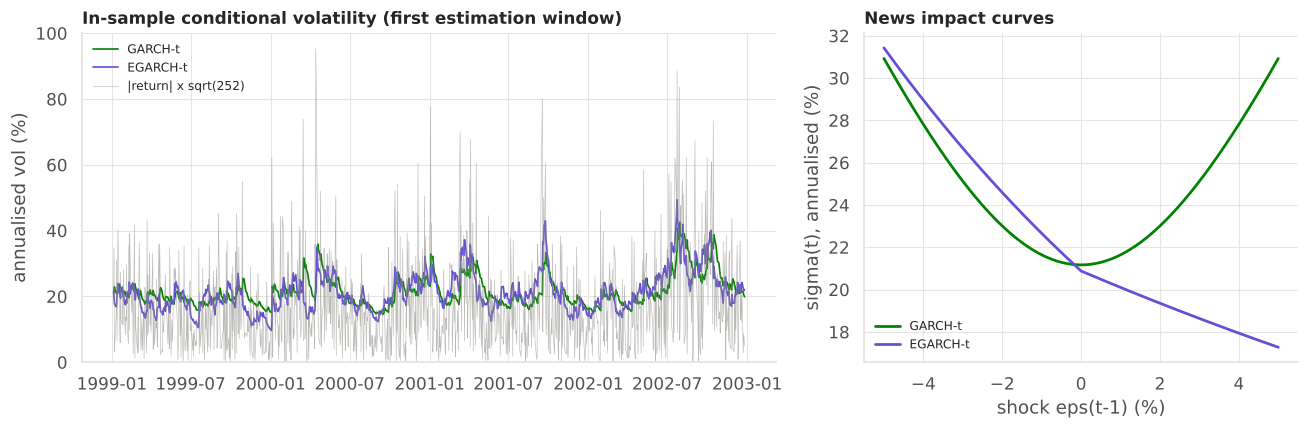

13:15:59 | INFO    | GARCH-t standardised residuals (in-sample): Ljung-Box on z^2 p-values at lags 10/20 = [0.823, 0.833]


13:15:59 | INFO    | Raw returns, same window: Ljung-Box on r^2 p-values = [0.0, 0.0]


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
for name, c in (("GARCH-t", PAL["green"]), ("EGARCH-t", PAL["violet"])):
    axes[0].plot(y_first.index, first_fit[name].conditional_volatility * np.sqrt(ANN), color=c, lw=1.1, label=name)
axes[0].plot(y_first.index, y_first.abs() * np.sqrt(ANN), color=PAL["muted"], lw=0.4, alpha=0.6, label="|return| x sqrt(252)")
axes[0].set_ylim(0, None); axes[0].set_ylabel("annualised vol (%)")
axes[0].set_title("In-sample conditional volatility (first estimation window)"); axes[0].legend(fontsize=8)

# News impact curves at sigma_{t-1} = long-run level
eps = np.linspace(-5, 5, 401)
for name, c in (("GARCH-t", PAL["green"]), ("EGARCH-t", PAL["violet"])):
    pr = first_fit[name].params
    if GARCH_SPECS[name]["vol"] == "GARCH":
        s2_bar = pr["omega"] / (1 - pr["alpha[1]"] - pr["beta[1]"])
        s2 = pr["omega"] + pr["alpha[1]"] * eps ** 2 + pr["beta[1]"] * s2_bar
    else:
        ln_s2_bar = pr["omega"] / (1 - pr["beta[1]"])
        zz = eps / np.sqrt(np.exp(ln_s2_bar))
        s2 = np.exp(pr["omega"] + pr["alpha[1]"] * (np.abs(zz) - np.sqrt(2 / np.pi)) + pr["gamma[1]"] * zz + pr["beta[1]"] * ln_s2_bar)
    axes[1].plot(eps, np.sqrt(s2 * ANN), color=c, lw=1.8, label=name)
axes[1].set_xlabel("shock eps(t-1) (%)"); axes[1].set_ylabel("sigma(t), annualised (%)")
axes[1].set_title("News impact curves"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

z_in = first_fit["GARCH-t"].std_resid.dropna()
lb_z = acorr_ljungbox(z_in ** 2, lags=[10, 20])
log.info("GARCH-t standardised residuals (in-sample): Ljung-Box on z^2 p-values at lags 10/20 = %s",
         lb_z["lb_pvalue"].round(3).tolist())
log.info("Raw returns, same window: Ljung-Box on r^2 p-values = %s",
         acorr_ljungbox(y_first ** 2, lags=[10, 20])["lb_pvalue"].round(4).tolist())

**Interpretation.** Persistence close to one means volatility shocks decay slowly (half-lives of weeks to months). The t-likelihood yields a finite $\nu$ even *after* conditioning on volatility: the conditional distribution is itself fat-tailed, but much less so than the unconditional one. The EGARCH asymmetry coefficient $\gamma$ is negative and large relative to its standard error, and the news-impact curve is visibly steeper for negative shocks, which a symmetric GARCH cannot represent. Standardising returns by the GARCH volatility removes most of the autocorrelation in squared returns (Ljung–Box on $z_t^2$ vs $r_t^2$, logged above). The likelihood-based criteria favour the t and the asymmetric specifications in-sample; whether that translates into better **out-of-sample** risk forecasts is what the backtest decides.

### 7.4 Rolling out-of-sample engine

For each refit date $t_k \in \{T_0, T_0+21, T_0+42, \dots\}$:

1. Estimate on $y_{t_k-W}, \dots, y_{t_k-1}$ with `arch`, twice: warm-started at the previous parameters and from `arch`'s default starting values. Among the admissible solutions, the one with the higher log-likelihood is kept. Warm starts alone are path-dependent: in development, EGARCH-t's $\nu$ drifted to the flat $\nu \to \infty$ region and stayed there for a decade.
2. **Admissibility.** A "converged" optimiser is not enough. An estimate is rejected if it is explosive ($\alpha+\beta > 1$), implausible ($|\mu| > 1\%$/day, $\nu$ stuck at its lower bound, EGARCH $\beta \notin (0,1)$ or size effect $\alpha \le 0$), or if its **unclipped** in-sample volatility filter is non-finite or leaves $[0.05, 15]\times$ the window's sample standard deviation. These checks use the estimation window only. If no admissible estimate is found, the previous refit's parameters are reused. Every event is logged and counted.
3. GARCH estimates **at the unit-persistence boundary** ($\alpha+\beta = 1$, IGARCH) are accepted and flagged. The unconditional variance does not exist, but the one-step-ahead forecast is perfectly well defined, and rejecting these estimates would freeze the model at pre-crisis parameters exactly when volatility regimes shift.
4. For each target $t$ in the block $[t_k, t_k+21)$, the variance recursion runs with the *fixed* parameters $\hat\theta_{t_k}$ over data up to $t-1$, and the one-step forecast is $\hat\sigma_t$.

**Why the forecasts use our own recursion rather than `arch`'s `forecast()`.** During estimation, `arch` bounds the conditional variance inside the likelihood. This is numerically convenient, but it can **mask an unstable EGARCH estimate**. When the size effect $\alpha$ is negative and the leverage term dominates, a large positive shock *shrinks* $\sigma_t$, which inflates the next standardised shock $z_t = \varepsilon_t/\sigma_t$, and the recursion can diverge. This is the EGARCH *invertibility* problem (Straumann & Mikosch, 2006; Wintenberger, 2013): the filtered volatility is no longer a stable function of past returns. The in-sample fit looks normal because of the bounds, while the unbounded one-step forecast explodes. During development, `arch`'s forecast from one such fit returned a one-day volatility of over 200%, and relaxing the $\alpha > 0$ restriction let through estimates whose filters diverged out of sample. The two recursions in the engine are the textbook equations with `arch`'s backcast initialisation. They are checked below to reproduce `arch`'s forecasts on well-behaved fits, and they make any instability visible instead of clipping it away.

A **look-ahead test** follows the engine: future returns are overwritten with noise and the forecasts made before that date must remain bit-for-bit identical.

In [16]:
def rolling_garch(y: pd.Series, spec_name: str, first_target: int, window: int, refit_every: int,
                  last_target: int | None = None, keep_resid: bool = False) -> dict:
    # Rolling one-step-ahead forecasts of (mu, sigma, nu) in the units of y, for targets first_target..last_target.
    # Parameters for target t are estimated on y[t_k-window : t_k] with refit date t_k <= t; the variance
    # recursion for target t uses y up to t-1 only. Acceptance decisions use estimation-window data only.
    spec = GARCH_SPECS[spec_name]
    y_arr, n = y.to_numpy(dtype=float), len(y)
    last_target = n - 1 if last_target is None else last_target
    if first_target - window < 0 or last_target >= n:
        raise ValueError("invalid target range")
    n_t = last_target - first_target + 1
    mu_f, sig_f, nu_f = np.full(n_t, np.nan), np.full(n_t, np.nan), np.full(n_t, np.nan)
    fit_log, blocks, prev, rejections = [], [], None, []
    t_wall = time.perf_counter()
    for k, t_k in enumerate(range(first_target, last_target + 1, refit_every)):
        date = y.index[t_k].date()
        block_end = min(t_k + refit_every, last_target + 1)           # targets t_k .. block_end-1
        data = y_arr[t_k - window:block_end - 1]                        # returns up to the last origin
        sd_est = data[:window].std(ddof=1)
        params, status, n_warn, cands = None, None, 0, []
        attempts = [("warm", prev), ("cold", None)] if prev is not None else [("cold", None)]
        for label, sv in attempts:                                      # both starts: avoids path dependence
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                try:
                    res = make_model(y.iloc[t_k - window:t_k], spec).fit(
                        disp="off", starting_values=None if sv is None else sv.values, options={"maxiter": 1_000})
                except Exception as exc:                                 # numerical failure inside the optimiser
                    res = None
                    log.warning("%s refit %s: optimiser raised %s: %s", spec_name, date, type(exc).__name__, exc)
            n_warn += sum(issubclass(w.category, ConvergenceWarning) for w in caught)
            if res is None:
                issue = "optimiser exception"
            elif res.convergence_flag != 0:
                issue = f"convergence flag {res.convergence_flag}"
            else:
                issue = admissibility_issue(res.params, spec)
                if issue is None:                                        # in-sample filter only: no look-ahead
                    issue = filter_issue(filter_volatility(data[:window], res.params, spec), sd_est)
            if issue is None:
                cands.append((res.loglikelihood, label, res.params))
            else:
                log.debug("%s refit %s (%s start): rejected -> %s", spec_name, date, label, issue)
                rejections.append({"model": spec_name, "refit_date": y.index[t_k], "start": label, "reason": issue})
        if cands:
            ll, label, params = max(cands, key=lambda c: c[0])
            status = "ok" if (label == "warm" or prev is None) else (
                "ok (cold start, higher LL)" if len(cands) == 2 else "ok (cold start only)")
            if spec["vol"] == "GARCH" and persistence(params, spec) > 1 - 1e-6:
                status += " [IGARCH boundary]"
        else:
            if prev is None:
                raise RuntimeError(f"{spec_name}: first estimation failed, no parameters to fall back on")
            log.warning("%s refit %s: no admissible estimate -> reusing previous parameters", spec_name, date)
            params, status = prev, "fallback: previous parameters"
        prev = params.copy()

        sig_path = filter_volatility(data, params, spec)                  # sigma for positions 0..len(data)
        sig_block = sig_path[window:]                                     # targets t_k .. block_end-1
        assert len(sig_block) == block_end - t_k, "forecast block misaligned"
        if not (np.isfinite(sig_block).all() and (sig_block > 0).all()):
            raise RuntimeError(f"{spec_name} {date}: non-finite out-of-sample volatility forecast")
        sl = slice(t_k - first_target, block_end - first_target)
        mu_f[sl], sig_f[sl] = params["mu"], sig_block
        if "nu" in params.index:
            nu_f[sl] = params["nu"]
        if keep_resid:
            blocks.append(dict(t_k=t_k, block_end=block_end, g0=t_k - window,
                               z=(data - params["mu"]) / sig_path[:-1]))
        fit_log.append({"refit_date": y.index[t_k], "status": status, "convergence_warnings": n_warn,
                        "persistence": persistence(params, spec), **params.to_dict()})
        if (k + 1) % 50 == 0:
            log.info("%s: %d refits done (last %s), %.1fs elapsed", spec_name, k + 1, date, time.perf_counter() - t_wall)
    fit_log = pd.DataFrame(fit_log).set_index("refit_date")
    counts = fit_log["status"].value_counts().to_dict()
    log.info("%s: %d refits in %.1fs | status counts %s | convergence warnings %d",
             spec_name, len(fit_log), time.perf_counter() - t_wall, counts, int(fit_log["convergence_warnings"].sum()))
    return dict(mu=mu_f, sigma=sig_f, nu=nu_f, fit_log=fit_log, blocks=blocks, rejections=pd.DataFrame(rejections))

In [17]:
# Validation of the hand-written recursions against arch on the first (well-behaved) estimation window:
# the one-step forecast must coincide with arch's own forecast.
rows = []
for name, spec in GARCH_SPECS.items():
    res = first_fit[name]
    mine = filter_volatility(y_first.to_numpy(), res.params, spec)[-1]
    arch_fc = float(np.sqrt(res.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]))
    rows.append({"model": name, "own recursion": mine, "arch forecast": arch_fc, "abs diff": abs(mine - arch_fc)})
    assert np.isclose(mine, arch_fc, rtol=1e-8), f"{name}: recursion does not reproduce arch"
display(pd.DataFrame(rows).set_index("model"))
log.info("Own GARCH/EGARCH recursions reproduce arch's one-step forecasts on the first window")

,own recursion,arch forecast,abs diff
model,,,
GARCH-N,1.198608,1.198608,0.0
GARCH-t,1.208870,1.208870,0.0
EGARCH-N,1.370984,1.370984,0.0
EGARCH-t,1.382387,1.382387,0.0


13:15:59 | INFO    | Own GARCH/EGARCH recursions reproduce arch's one-step forecasts on the first window


In [18]:
# ------------------------------------------------------------------ look-ahead (leakage) test
# Overwrite every return from day `cut` onward with noise: forecasts for targets <= cut must not change.
n_short = T0 + 3 * REFIT_EVERY + 10
cut = T0 + REFIT_EVERY + 7                       # in the middle of the second block
y_short = y_pct.iloc[:n_short]
y_tampered = y_short.copy()
y_tampered.iloc[cut:] = np.random.default_rng(0).normal(0, 5, n_short - cut)
for spec_name in ("GARCH-t", "EGARCH-N"):
    a_run = rolling_garch(y_short, spec_name, T0, W_EST, REFIT_EVERY)
    b_run = rolling_garch(y_tampered, spec_name, T0, W_EST, REFIT_EVERY)
    m = cut - T0 + 1                              # targets T0 .. cut
    assert np.array_equal(a_run["sigma"][:m], b_run["sigma"][:m]), f"{spec_name}: LOOK-AHEAD DETECTED"
    assert not np.allclose(a_run["sigma"][m:], b_run["sigma"][m:]), "tampering had no effect: test is vacuous"
hs_a = empirical_var_es(window_matrix(y_short.to_numpy(), np.arange(T0, n_short), W_UNC), 0.99)[0]
hs_b = empirical_var_es(window_matrix(y_tampered.to_numpy(), np.arange(T0, n_short), W_UNC), 0.99)[0]
assert np.array_equal(hs_a[:cut - T0 + 1], hs_b[:cut - T0 + 1]), "HS: LOOK-AHEAD DETECTED"
log.info("Look-ahead test passed: forecasts up to %s are identical when all later returns are replaced by noise",
         y_pct.index[cut].date())

13:15:59 | INFO    | GARCH-t: 4 refits in 0.2s | status counts {'ok': 2, 'ok (cold start, higher LL)': 2} | convergence warnings 0


13:15:59 | INFO    | GARCH-t: 4 refits in 0.1s | status counts {'ok': 2, 'ok (cold start, higher LL)': 2} | convergence warnings 0


13:15:59 | INFO    | EGARCH-N: 4 refits in 0.1s | status counts {'ok': 4} | convergence warnings 0


13:15:59 | INFO    | EGARCH-N: 4 refits in 0.1s | status counts {'ok': 3, 'ok (cold start, higher LL)': 1} | convergence warnings 0


13:15:59 | INFO    | Look-ahead test passed: forecasts up to 2003-02-07 are identical when all later returns are replaced by noise


In [19]:
garch_runs = {}
for name in GARCH_SPECS:
    log.info("Rolling estimation: %s (window %d, refit every %d days, %d targets)", name, W_EST, REFIT_EVERY, len(OOS_IDX))
    garch_runs[name] = rolling_garch(y_pct, name, T0, W_EST, REFIT_EVERY, keep_resid=(name == "GARCH-N"))

fail_tbl = pd.DataFrame({n: run["fit_log"]["status"].value_counts() for n, run in garch_runs.items()}).fillna(0).astype(int).T
fail_tbl["convergence warnings"] = [int(run["fit_log"]["convergence_warnings"].sum()) for run in garch_runs.values()]
print("Outcome of the re-estimations (number of refit dates)")
display(fail_tbl)
rej = pd.concat([run["rejections"] for run in garch_runs.values() if len(run["rejections"])], ignore_index=True)
if len(rej):
    rej["reason"] = rej["reason"].str.replace(r"[-\d.]+(%/day)?\)?$", "", regex=True).str.replace(r"\($", "", regex=True).str.strip(" :(")
    print("Rejected candidate estimates (warm or cold start) by reason")
    display(rej.groupby(["model", "reason"]).size().rename("count").to_frame())

13:15:59 | INFO    | Rolling estimation: GARCH-N (window 1000, refit every 21 days, 4030 targets)


13:16:01 | INFO    | GARCH-N: 50 refits done (last 2007-01-31), 1.5s elapsed


13:16:02 | INFO    | GARCH-N: 100 refits done (last 2011-03-31), 2.8s elapsed


13:16:03 | INFO    | GARCH-N: 150 refits done (last 2015-06-04), 4.0s elapsed


13:16:04 | INFO    | GARCH-N: 192 refits in 5.1s | status counts {'ok': 115, 'ok (cold start, higher LL)': 77} | convergence warnings 0


...

13:16:40 | INFO    | EGARCH-t: 192 refits in 16.8s | status counts {'ok': 115, 'ok (cold start, higher LL)': 63, 'fallback: previous parameters': 14} | convergence warnings 4


Outcome of the re-estimations (number of refit dates)


status,fallback: previous parameters,ok,ok (cold start only),"ok (cold start, higher LL)","ok (cold start, higher LL) [IGARCH boundary]",ok [IGARCH boundary],convergence warnings
GARCH-N,0,115,0,77,0,0,0
GARCH-t,0,92,0,57,16,27,0
EGARCH-N,13,109,2,68,0,0,1
EGARCH-t,14,115,0,63,0,0,4


Rejected candidate estimates (warm or cold start) by reason


count
model    reason                                                   
EGARCH-N convergence flag                                        1
         implausible mean                                        3
         size effect alpha outside (0,1): -0.0178 (filte...      1
         size effect alpha outside (0,1): -0.0214 (filte...      1
         size effect alpha outside (0,1): -0.0216 (filte...      1
         size effect alpha outside (0,1): -0.0218 (filte...      1
         size effect alpha outside (0,1): -0.0222 (filte...      1
         size effect alpha outside (0,1): -0.0228 (filte...      1
         size effect alpha outside (0,1): -0.0229 (filte...      1
         size effect alpha outside (0,1): -0.0230 (filte...      1
         size effect alpha outside (0,1): -0.0235 (filte...      1
         size effect alpha outside (0,1): -0.0236 (filte...      1
         size effect alpha outside (0,1): -0.0239 (filte...      1
         size effect alpha outside (0,1): -0.0241 (filte...      1
         size effect alpha outside (0,1): -0.0245 (filte...      1
         size effect alpha outside (0,1): -0.0254 (filte...      1
         size effect alpha outside (0,1): -0.0264 (filte...      2
         size effect alpha outside (0,1): -0.0266 (filte...      1
         size effect alpha outside (0,1): -0.0268 (filte...      1
         size effect alpha outside (0,1): -0.0269 (filte...      1
         size effect alpha outside (0,1): -0.0279 (filte...      1
         size effect alpha outside (0,1): -0.0281 (filte...      1
         size effect alpha outside (0,1): -0.0288 (filte...      1
         size effect alpha outside (0,1): -0.0295 (filte...      1
         size effect alpha outside (0,1): -0.0301 (filte...      1
EGARCH-t beta outside (0,1)                                      2
         convergence flag                                        4
         implausible mean                                        4
         size effect alpha outside (0,1): -0.0094 (filte...      1
         size effect alpha outside (0,1): -0.0174 (filte...      1
         size effect alpha outside (0,1): -0.0226 (filte...      1
         size effect alpha outside (0,1): -0.0229 (filte...      1
         size effect alpha outside (0,1): -0.0246 (filte...      1
         size effect alpha outside (0,1): -0.0250 (filte...      1
         size effect alpha outside (0,1): -0.0251 (filte...      1
         size effect alpha outside (0,1): -0.0255 (filte...      1
         size effect alpha outside (0,1): -0.0270 (filte...      1
         size effect alpha outside (0,1): -0.0272 (filte...      1
         size effect alpha outside (0,1): -0.0289 (filte...      2
         size effect alpha outside (0,1): -0.0295 (filte...      1
         size effect alpha outside (0,1): -0.0296 (filte...      1
         size effect alpha outside (0,1): -0.0300 (filte...      1
         size effect alpha outside (0,1): -0.0304 (filte...      1
         size effect alpha outside (0,1): -0.0306 (filte...      1
         size effect alpha outside (0,1): -0.0313 (filte...      1
         size effect alpha outside (0,1): -0.0349 (filte...      1

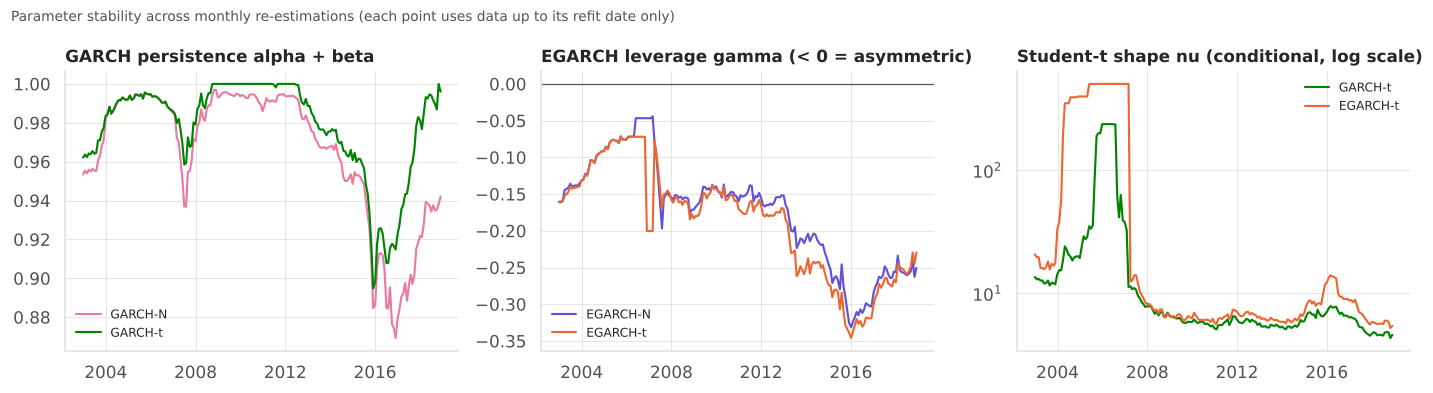

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for name, c in (("GARCH-N", PAL["magenta"]), ("GARCH-t", PAL["green"])):
    fl = garch_runs[name]["fit_log"]
    axes[0].plot(fl.index, fl["persistence"], color=c, lw=1.4, label=name)
for name, c in (("EGARCH-N", PAL["violet"]), ("EGARCH-t", PAL["orange"])):
    fl = garch_runs[name]["fit_log"]
    axes[1].plot(fl.index, fl["gamma[1]"], color=c, lw=1.4, label=name)
for name, c in (("GARCH-t", PAL["green"]), ("EGARCH-t", PAL["orange"])):
    fl = garch_runs[name]["fit_log"]
    axes[2].plot(fl.index, fl["nu"], color=c, lw=1.4, label=name)
axes[0].set_title("GARCH persistence alpha + beta"); axes[1].set_title("EGARCH leverage gamma (< 0 = asymmetric)")
axes[2].set_title("Student-t shape nu (conditional, log scale)"); axes[2].set_yscale("log")
axes[1].axhline(0, color=PAL["ink2"], lw=0.8)
for ax in axes:
    ax.legend(fontsize=8); ax.xaxis.set_major_locator(mdates.YearLocator(4))
fig.suptitle("Parameter stability across monthly re-estimations (each point uses data up to its refit date only)",
             x=0.01, ha="left", fontsize=9, color=PAL["ink2"])
fig.tight_layout(); plt.show()

**Parameter stability** is itself a validation diagnostic: parameters that wander erratically between monthly refits would make the VaR jump for statistical rather than economic reasons. Persistence stays high throughout (GARCH-t sits at the IGARCH boundary through the post-2008 windows) and the leverage coefficient never changes sign. The conditional $\nu$ is much larger than the unconditional one of Section 3, so conditioning on volatility explains most of the kurtosis. In long calm windows the t-likelihood is nearly flat in $\nu$ and the estimate runs to its upper bound: the fitted conditional distribution becomes Gaussian just before volatility returns. This is a mechanism for under-coverage after calm periods that a validator should look for.

## 8. Out-of-Sample Backtesting

### 8.1 Assembling the forecasts

All models now produce $(\mathrm{VaR}_t, \mathrm{ES}_t)$ for the same out-of-sample days. The unconditional models use the trailing 500-day window. For the Student-t models, $\nu$ is re-estimated every 21 days on the then-current window. The Monte Carlo model draws $N = 10{,}000$ fresh innovations per day (seeded).

In [21]:
MODELS_BENCH = ["HS", "Gaussian", "Student-t", "MC Student-t", "GARCH-N", "GARCH-t", "EGARCH-N", "EGARCH-t"]
fc = {}                                              # fc[(model, alpha)] = (VaR array, ES array), decimal units

# --- unconditional models ---------------------------------------------------------
win_unc = window_matrix(r, OOS_IDX, W_UNC)
mu_u, sd_u = win_unc.mean(axis=1), win_unc.std(axis=1, ddof=1)
nu_u = np.empty(len(OOS_IDX))
t_wall = time.perf_counter()
for i in range(0, len(OOS_IDX), REFIT_EVERY):
    nu_u[i:i + REFIT_EVERY] = fit_std_t_nu((win_unc[i] - mu_u[i]) / sd_u[i])
log.info("Unconditional Student-t: %d nu estimates in %.1fs (median %.2f, range %.2f-%.2f)",
         len(range(0, len(OOS_IDX), REFIT_EVERY)), time.perf_counter() - t_wall, np.median(nu_u), nu_u.min(), nu_u.max())

for a in ALPHAS:
    fc[("HS", a)] = hs_by_window[(W_UNC, a)]
    fc[("Gaussian", a)] = var_es_normal(mu_u, sd_u, a)
    fc[("Student-t", a)] = var_es_std_t(mu_u, sd_u, a, nu_u)

# --- Monte Carlo Student-t (chunked, seeded) ----------------------------------------
rng_bt = np.random.default_rng(SEED + 2)
mc_v = {a: np.empty(len(OOS_IDX)) for a in ALPHAS}
mc_e = {a: np.empty(len(OOS_IDX)) for a in ALPHAS}
t_wall = time.perf_counter()
for i in range(0, len(OOS_IDX), 250):
    sl = slice(i, min(i + 250, len(OOS_IDX)))
    nu_c = nu_u[sl][:, None]
    sims = mu_u[sl][:, None] + sd_u[sl][:, None] * rng_bt.standard_t(nu_c, size=(len(nu_c), N_MC_BACKTEST)) * std_t_scale(nu_c)
    for a in ALPHAS:
        mc_v[a][sl], mc_e[a][sl] = empirical_var_es(sims, a)
for a in ALPHAS:
    fc[("MC Student-t", a)] = (mc_v[a], mc_e[a])
log.info("MC Student-t: %d days x %d draws in %.1fs", len(OOS_IDX), N_MC_BACKTEST, time.perf_counter() - t_wall)

# --- GARCH family -------------------------------------------------------------------
for name, run in garch_runs.items():
    for a in ALPHAS:
        if GARCH_SPECS[name]["dist"] == "normal":
            v, e = var_es_normal(run["mu"], run["sigma"], a)
        else:
            v, e = var_es_std_t(run["mu"], run["sigma"], a, run["nu"])
        fc[(name, a)] = (v / 100.0, e / 100.0)        # percent -> decimal

for key, (v, e) in fc.items():
    assert v.shape == (len(OOS_IDX),) and np.isfinite(v).all() and np.isfinite(e).all(), key
    assert (v > 0).all() and (e >= v - 1e-12).all(), f"{key}: VaR must be positive and ES >= VaR"
log.info("Forecast matrix complete: %d model x level combinations, %d days each", len(fc), len(OOS_IDX))

13:16:41 | INFO    | Unconditional Student-t: 192 nu estimates in 0.7s (median 4.17, range 2.65-200.00)


13:16:43 | INFO    | MC Student-t: 4030 days x 10000 draws in 2.4s


13:16:43 | INFO    | Forecast matrix complete: 16 model x level combinations, 4030 days each


### 8.2 Test statistics

Let $T$ be the number of forecasts, $x = \sum_t I_t$ the number of violations and $\hat\pi = x/T$.

**A. Kupiec (1995) proportion-of-failures test.** $H_0: \mathbb P(I_t = 1) = p$, with $I_t$ i.i.d. Bernoulli:
$$LR_{uc} = -2\ln\frac{(1-p)^{T-x}p^{x}}{(1-\hat\pi)^{T-x}\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1.$$

**B. Christoffersen (1998) independence test.** With $n_{ij}$ = number of days in state $j$ preceded by a day in state $i$, $\hat\pi_{01} = n_{01}/(n_{00}+n_{01})$, $\hat\pi_{11} = n_{11}/(n_{10}+n_{11})$, $\hat\pi_2 = (n_{01}+n_{11})/(T-1)$. Against a first-order Markov alternative:
$$LR_{ind} = -2\ln\frac{(1-\hat\pi_2)^{n_{00}+n_{10}}\hat\pi_2^{\,n_{01}+n_{11}}}{(1-\hat\pi_{01})^{n_{00}}\hat\pi_{01}^{\,n_{01}}(1-\hat\pi_{11})^{n_{10}}\hat\pi_{11}^{\,n_{11}}} \;\xrightarrow{d}\; \chi^2_1.$$
*Limitations:* it only detects **first-order** dependence (two violations three days apart are invisible); with few violations $n_{11}$ is often 0 and the $\chi^2$ approximation is poor; it has no power against dependence on other variables (e.g. the volatility level).

**C. Conditional coverage.** $H_0: \pi_{01} = \pi_{11} = p$:
$$LR_{cc} = -2\ln\frac{(1-p)^{n_{00}+n_{10}}p^{\,n_{01}+n_{11}}}{(1-\hat\pi_{01})^{n_{00}}\hat\pi_{01}^{\,n_{01}}(1-\hat\pi_{11})^{n_{10}}\hat\pi_{11}^{\,n_{11}}} \;\xrightarrow{d}\; \chi^2_2,$$
computed exactly on the $T-1$ transitions, so that $LR_{cc} = LR_{uc}^{(T-1)} + LR_{ind}$.

**D. Dynamic Quantile test** (Engle & Manganelli, 2004). Let $\mathrm{Hit}_t = I_t - p$. Under correct conditional coverage $\mathbb E[\mathrm{Hit}_t \mid \mathcal F_{t-1}] = 0$, so $\mathrm{Hit}_t$ is uncorrelated with any $\mathcal F_{t-1}$-measurable regressor. We use $X_t = (1, \mathrm{Hit}_{t-1}, \dots, \mathrm{Hit}_{t-4}, \mathrm{VaR}_t)$ ($K = 4$ lags) and the out-of-sample statistic
$$DQ = \frac{\mathrm{Hit}^\top X (X^\top X)^{-1} X^\top \mathrm{Hit}}{p(1-p)} \;\xrightarrow{d}\; \chi^2_{q},$$
with $q = \operatorname{rank}(X) = K + 2 = 6$ under the null of i.i.d. Bernoulli($p$) hits. Including $\mathrm{VaR}_t$ gives the test power against forecasts that are **systematically too low when they are high** (or vice versa), the typical failure of unconditional models. If a lagged hit column is constant (no violations), $X$ loses rank; the pseudo-inverse is used and $q$ is reduced to the actual rank. Because hits are rare at 99%, the $\chi^2$ approximation is unreliable in finite samples. We therefore also report an **exact Monte Carlo p-value** (Dufour, 2006): under $H_0$ the hits are i.i.d. Bernoulli($p$) and independent of the (predetermined) VaR path, so we simulate 2,000 hit sequences against the observed VaR path and compute $\hat p = (1 + \#\{DQ^{(s)} \ge DQ\})/(2{,}001)$. Pass/fail flags use this p-value, and the simulated 5% critical value is reported next to the $\chi^2_6$ value of 12.59.

**E. Expected Shortfall.** VaR tests say nothing about the *size* of losses beyond the VaR. Two complementary tools:

* **Exceedance-residual test** (McNeil & Frey, 2000). If both forecasts are correct, $\mathbb E[L_t - \mathrm{ES}_t \mid L_t > \mathrm{VaR}_t, \mathcal F_{t-1}] = 0$. Since $\mathrm{ES}_t$ is $\mathcal F_{t-1}$-measurable, the scale-free residuals $e_t = (L_t - \mathrm{ES}_t)/\mathrm{ES}_t$ on violation days also have mean zero. We test $H_0: \mathbb E e = 0$ against $H_1: \mathbb E e > 0$ (ES underestimated) with a one-sided **bootstrap** of the studentised mean (residuals re-centred under $H_0$, 10,000 resamples). The test is conditional on violations, so it also depends on the VaR, and with few violations its power is low.
* **FZ0 joint scoring function** (Fissler & Ziegel, 2016; Patton, Ziegel & Chen, 2019). With $v_t = -\mathrm{VaR}_t$ and $e_t = -\mathrm{ES}_t < 0$ (return quantile and tail mean):
$$S_{FZ0}(r_t, v_t, e_t) = -\frac{1}{p\,e_t}\,\mathbb 1\{r_t \le v_t\}(v_t - r_t) + \frac{v_t}{e_t} + \ln(-e_t) - 1.$$
VaR alone is *not* elicitable jointly with ES unless they are scored together, and $S_{FZ0}$ is **strictly consistent** for the pair: its expected value is minimised by the true $(\mathrm{VaR}, \mathrm{ES})$. Lower average scores are better, it is invariant to rescaling the returns, and differences between models are tested with the **Diebold–Mariano** statistic using a Newey–West (Bartlett) long-run variance with $\lfloor 4(T/100)^{2/9} \rfloor$ lags. We also report the quantile (tick) loss $S_Q = (p - \mathbb 1\{r_t \le v_t\})(r_t - v_t)$, strictly consistent for VaR alone.

**Boundary cases.** All likelihoods use $x\log y$ with the convention $0 \cdot \log 0 = 0$ (`scipy.special.xlogy`), so zero violations, all violations, or $n_{11} = 0$ yield finite statistics. When a statistic is undefined (independence with no violation in a "previous" position), the p-value is reported as `NaN`, not as a pass.

In [22]:
def kupiec_pof(hits: np.ndarray, p: float) -> dict:
    T, x = len(hits), int(hits.sum())
    pi = x / T
    ll0 = xlogy(T - x, 1 - p) + xlogy(x, p)
    ll1 = xlogy(T - x, 1 - pi) + xlogy(x, pi)
    lr = max(-2 * (ll0 - ll1), 0.0)
    return dict(T=T, x=x, rate=pi, LR_uc=lr, p_uc=stats.chi2.sf(lr, 1))


def christoffersen(hits: np.ndarray, p: float) -> dict:
    h0, h1 = hits[:-1].astype(int), hits[1:].astype(int)
    n00, n01 = int(((h0 == 0) & (h1 == 0)).sum()), int(((h0 == 0) & (h1 == 1)).sum())
    n10, n11 = int(((h0 == 1) & (h1 == 0)).sum()), int(((h0 == 1) & (h1 == 1)).sum())
    pi01 = n01 / (n00 + n01) if n00 + n01 else 0.0
    pi11 = n11 / (n10 + n11) if n10 + n11 else 0.0
    pi2 = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_markov = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    ll_iid = xlogy(n00 + n10, 1 - pi2) + xlogy(n01 + n11, pi2)
    ll_null = xlogy(n00 + n10, 1 - p) + xlogy(n01 + n11, p)
    lr_ind = max(-2 * (ll_iid - ll_markov), 0.0)
    lr_cc = max(-2 * (ll_null - ll_markov), 0.0)
    defined = (n10 + n11) > 0 and (n01 + n11) > 0          # at least one violation in a 'previous' position
    return dict(n00=n00, n01=n01, n10=n10, n11=n11, pi01=pi01, pi11=pi11,
                LR_ind=lr_ind, p_ind=stats.chi2.sf(lr_ind, 1) if defined else np.nan,
                LR_cc=lr_cc, p_cc=stats.chi2.sf(lr_cc, 2))


def _dq_stat(hits: np.ndarray, var: np.ndarray, p: float, lags: int):
    hit = hits.astype(float) - p
    T = len(hit)
    X = np.column_stack([np.ones(T - lags)] + [hit[lags - 1 - k:T - 1 - k] for k in range(lags)] + [var[lags:]])
    y = hit[lags:]
    beta = np.linalg.pinv(X.T @ X) @ (X.T @ y)
    return float(y @ X @ beta) / (p * (1 - p)), int(np.linalg.matrix_rank(X)), beta


def dq_test(hits: np.ndarray, var: np.ndarray, p: float, lags: int = DQ_LAGS, n_sim: int = 0, rng=None) -> dict:
    """Engle-Manganelli DQ test; asymptotic chi2 p-value and, if n_sim > 0, an exact Monte Carlo p-value
    (Dufour, 2006) obtained by simulating i.i.d. Bernoulli(p) hits against the observed VaR path."""
    dq, rank, beta = _dq_stat(hits, var, p, lags)
    out = dict(DQ=dq, DQ_df=rank, p_dq=stats.chi2.sf(dq, rank),
               **{f"dq_b_hit{k + 1}": beta[k + 1] for k in range(lags)})
    if n_sim:
        sims = np.array([_dq_stat(rng.random(len(hits)) < p, var, p, lags)[0] for _ in range(n_sim)])
        out["p_dq_mc"] = (1 + np.sum(sims >= dq)) / (n_sim + 1)
        out["DQ_crit5_mc"] = float(np.quantile(sims, 0.95))          # finite-sample 5% critical value
    return out


def es_exceedance_test(losses, var, es, rng, n_boot: int = N_BOOT) -> dict:
    viol = losses > var
    e = (losses[viol] - es[viol]) / es[viol]
    n = len(e)
    if n < 5:
        return dict(n_exceed=n, mean_exceed_resid=np.nan, p_es=np.nan)
    sd = e.std(ddof=1)
    t_obs = e.mean() / (sd / np.sqrt(n)) if sd > 0 else np.inf
    e0 = e - e.mean()                                           # impose H0: mean zero
    idx = rng.integers(0, n, size=(n_boot, n))
    b = e0[idx]
    t_b = b.mean(axis=1) / (b.std(axis=1, ddof=1) / np.sqrt(n))
    return dict(n_exceed=n, mean_exceed_resid=e.mean(), p_es=float((t_b >= t_obs).mean()))


def fz0_loss(ret, var, es, p):
    v, e = -var, -es
    if np.any(e >= 0):
        raise ValueError("FZ0 requires ES > 0 (e < 0)")
    hit = (ret <= v).astype(float)
    return -hit * (v - ret) / (p * e) + v / e + np.log(-e) - 1.0


def quantile_loss(ret, var, p):
    v = -var
    return (p - (ret <= v)) * (ret - v)


def diebold_mariano(loss_a, loss_b) -> tuple[float, float]:
    """DM statistic for mean(loss_a - loss_b); negative => model a better. Newey-West HAC variance."""
    d = np.asarray(loss_a) - np.asarray(loss_b)
    T = len(d)
    u = d - d.mean()
    L = int(np.floor(4 * (T / 100) ** (2 / 9)))
    lrv = u @ u / T + 2 * sum((1 - k / (L + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, L + 1))
    stat = d.mean() / np.sqrt(lrv / T)
    return float(stat), float(2 * stats.norm.sf(abs(stat)))


def basel_zones(hits99: np.ndarray, block: int = 250) -> dict:
    nb = len(hits99) // block
    counts = hits99[:nb * block].reshape(nb, block).sum(axis=1)
    return dict(blocks=nb, green=int((counts <= 4).sum()), yellow=int(((counts >= 5) & (counts <= 9)).sum()),
                red=int((counts >= 10).sum()), max_exceptions=int(counts.max()))


# ---------------------------------------------------------------------- unit tests
p_ = 0.01
h = np.zeros(1000, bool); h[::100] = True                                   # exactly 10 = T p, evenly spaced
assert np.isclose(kupiec_pof(h, p_)["LR_uc"], 0.0) and np.isclose(kupiec_pof(h, p_)["p_uc"], 1.0)
assert kupiec_pof(np.zeros(1000, bool), p_)["LR_uc"] > 0                      # zero violations: finite, positive
assert np.isfinite(kupiec_pof(np.ones(50, bool), p_)["LR_uc"])                 # all violations: finite
c0 = christoffersen(np.zeros(500, bool), p_)
assert np.isnan(c0["p_ind"]) and np.isfinite(c0["LR_cc"])                    # undefined independence -> NaN
hc = np.zeros(1000, bool); hc[500:510] = True                                  # 10 consecutive violations
assert christoffersen(hc, p_)["p_ind"] < 1e-6 and kupiec_pof(hc, p_)["p_uc"] > 0.99   # right count, clustered
cc_chk = christoffersen(h, p_)
assert np.isclose(cc_chk["LR_cc"], kupiec_pof(h[1:], p_)["LR_uc"] + cc_chk["LR_ind"]), "LR_cc != LR_uc + LR_ind"
assert dq_test(np.zeros(500, bool), np.full(500, 0.02), p_)["DQ_df"] < DQ_LAGS + 2   # rank deficiency handled
rng_ut = np.random.default_rng(1)
z_ut = rng_ut.standard_normal(200_000)
v_n, e_n = var_es_normal(0.0, 1.0, 0.975)
fz_true = fz0_loss(z_ut, np.full_like(z_ut, v_n), np.full_like(z_ut, e_n), 0.025).mean()
fz_bad = fz0_loss(z_ut, np.full_like(z_ut, 0.8 * v_n), np.full_like(z_ut, 0.8 * e_n), 0.025).mean()
assert fz_true < fz_bad, "FZ0 does not prefer the true forecast"
log.info("Backtest unit tests passed (Kupiec/Christoffersen boundaries, LR_cc additivity, DQ rank, FZ0 consistency)")

13:16:43 | INFO    | Backtest unit tests passed (Kupiec/Christoffersen boundaries, LR_cc additivity, DQ rank, FZ0 consistency)


In [23]:
def backtest(model: str, alpha: float, var: np.ndarray, es: np.ndarray, rng) -> dict:
    p = tail_prob(alpha)
    hits = L_oos > var
    row = dict(model=model, alpha=alpha, T=len(hits), expected=len(hits) * p)
    row |= kupiec_pof(hits, p)
    row |= christoffersen(hits, p)
    row |= dq_test(hits, var, p, n_sim=N_DQ_SIM, rng=rng)
    row |= es_exceedance_test(L_oos, var, es, rng)
    row |= dict(avg_VaR=var.mean(), avg_ES=es.mean(),
                QL=quantile_loss(r_oos, var, p).mean(), FZ0=fz0_loss(r_oos, var, es, p).mean())
    if np.isclose(alpha, 0.99):
        row |= {f"basel_{k}": v for k, v in basel_zones(hits).items()}
    return row


rng_boot = np.random.default_rng(SEED + 3)
bt_rows = [backtest(m, a, *fc[(m, a)], rng_boot) for a in ALPHAS for m in MODELS_BENCH]
bt = pd.DataFrame(bt_rows).set_index(["alpha", "model"])
for a in ALPHAS:
    sub = bt.loc[a]
    log.info("alpha=%.2f: violations per model %s (expected %.1f)", a, sub["x"].to_dict(), sub["expected"].iloc[0])

detail_cols = ["T", "expected", "x", "rate", "LR_uc", "p_uc", "n01", "n11", "pi01", "pi11", "LR_ind", "p_ind",
               "LR_cc", "p_cc", "DQ", "DQ_df", "p_dq", "DQ_crit5_mc", "p_dq_mc"]
for a in ALPHAS:
    print(f"\nVaR backtests, alpha = {a:.0%} (expected violation rate {tail_prob(a):.0%})")
    display(bt.loc[a, detail_cols].round(4))

print("\nDQ regression: coefficients on lagged hits (99%). Positive values = a violation raises the probability of"
      " another one k days later; lags >= 2 are invisible to Christoffersen's first-order test.")
display(bt.loc[0.99, [f"dq_b_hit{k + 1}" for k in range(DQ_LAGS)]].rename(columns=lambda c: c.replace("dq_b_hit", "lag ")).round(3))

13:16:55 | INFO    | alpha=0.95: violations per model {'HS': 209, 'Gaussian': 227, 'Student-t': 258, 'MC Student-t': 256, 'GARCH-N': 231, 'GARCH-t': 244, 'EGARCH-N': 233, 'EGARCH-t': 245} (expected 201.5)


13:16:55 | INFO    | alpha=0.99: violations per model {'HS': 56, 'Gaussian': 105, 'Student-t': 83, 'MC Student-t': 82, 'GARCH-N': 90, 'GARCH-t': 63, 'EGARCH-N': 85, 'EGARCH-t': 66} (expected 40.3)



VaR backtests, alpha = 95% (expected violation rate 5%)


,T,expected,x,rate,LR_uc,p_uc,n01,n11,pi01,pi11,LR_ind,p_ind,LR_cc,p_cc,DQ,DQ_df,p_dq,DQ_crit5_mc,p_dq_mc
model,,,,,,,,,,,,,,,,,,,
HS,4030,201.5,209,0.0519,0.2905,0.5899,180,29,0.0471,0.1388,24.2749,0.0000,24.5693,0.0000,190.4882,6,0.0000,12.7486,0.0005
Gaussian,4030,201.5,227,0.0563,3.2692,0.0706,195,32,0.0513,0.1410,23.9302,0.0000,27.2127,0.0000,208.2612,6,0.0000,13.2376,0.0005
Student-t,4030,201.5,258,0.0640,15.3778,0.0001,221,37,0.0586,0.1434,22.4012,0.0000,37.8087,0.0000,238.5628,6,0.0000,12.3371,0.0005
MC Student-t,4030,201.5,256,0.0635,14.3462,0.0002,221,35,0.0586,0.1367,19.2773,0.0000,33.6522,0.0000,228.2339,6,0.0000,13.1630,0.0005
GARCH-N,4030,201.5,231,0.0573,4.3502,0.0370,218,13,0.0574,0.0563,0.0051,0.9431,4.3708,0.1124,16.5284,6,0.0112,13.0001,0.0145
GARCH-t,4030,201.5,244,0.0605,8.8664,0.0029,230,14,0.0608,0.0574,0.0470,0.8284,8.9358,0.0115,21.4940,6,0.0015,12.1870,0.0015
EGARCH-N,4030,201.5,233,0.0578,4.9460,0.0262,222,11,0.0585,0.0472,0.5424,0.4614,5.5049,0.0638,15.5090,6,0.0166,12.4442,0.0170
EGARCH-t,4030,201.5,245,0.0608,9.2759,0.0023,234,11,0.0618,0.0449,1.2584,0.2619,10.5572,0.0051,19.9453,6,0.0028,13.2452,0.0075



VaR backtests, alpha = 99% (expected violation rate 1%)


,T,expected,x,rate,LR_uc,p_uc,n01,n11,pi01,pi11,LR_ind,p_ind,LR_cc,p_cc,DQ,DQ_df,p_dq,DQ_crit5_mc,p_dq_mc
model,,,,,,,,,,,,,,,,,,,
HS,4030,40.3,56,0.0139,5.5099,0.0189,51,5,0.0128,0.0893,10.8239,0.0010,16.3417,0.0003,208.3797,6,0.0,15.0464,0.0005
Gaussian,4030,40.3,105,0.0261,72.7528,0.0000,92,13,0.0234,0.1238,22.1490,0.0000,94.9345,0.0000,481.5771,6,0.0,15.0044,0.0005
Student-t,4030,40.3,83,0.0206,34.9918,0.0000,74,9,0.0188,0.1084,16.6767,0.0000,51.6900,0.0000,310.2642,6,0.0,16.0699,0.0005
MC Student-t,4030,40.3,82,0.0203,33.5377,0.0000,73,9,0.0185,0.1098,17.0635,0.0000,50.6222,0.0000,317.2036,6,0.0,15.8956,0.0005
GARCH-N,4030,40.3,90,0.0223,45.8442,0.0000,87,3,0.0221,0.0333,0.4450,0.5047,46.3143,0.0000,108.2817,6,0.0,15.3335,0.0005
GARCH-t,4030,40.3,63,0.0156,11.0241,0.0009,60,3,0.0151,0.0476,2.7853,0.0951,13.8208,0.0010,89.6490,6,0.0,14.4404,0.0005
EGARCH-N,4030,40.3,85,0.0211,37.9737,0.0000,82,3,0.0208,0.0353,0.7095,0.3996,38.7057,0.0000,97.0698,6,0.0,15.6732,0.0005
EGARCH-t,4030,40.3,66,0.0164,13.8819,0.0002,64,2,0.0161,0.0303,0.6491,0.4204,14.5440,0.0007,79.3158,6,0.0,16.3227,0.0015



DQ regression: coefficients on lagged hits (99%). Positive values = a violation raises the probability of another one k days later; lags >= 2 are invisible to Christoffersen's first-order test.


,lag 1,lag 2,lag 3,lag 4
model,,,,
HS,0.050,0.090,0.073,0.110
Gaussian,0.075,0.104,0.050,0.084
Student-t,0.066,0.079,0.066,0.093
MC Student-t,0.068,0.093,0.052,0.094
GARCH-N,0.012,0.033,0.000,0.057
GARCH-t,0.032,0.060,-0.004,0.079
EGARCH-N,0.014,0.026,0.027,0.063
EGARCH-t,0.014,0.028,0.013,0.091


### 8.3 Reading the tests

* A **p-value** is the probability, under $H_0$ (correctly specified coverage), of a statistic at least as extreme as the one observed. A small p-value is evidence against the model. A large p-value is **not** evidence that the model is right: it may only mean the test lacks power.
* **Power at 99% is low.** With $T$ out-of-sample days and $p = 1\%$, the expected count is $Tp$ with standard deviation $\sqrt{Tp(1-p)}$. Over one year (250 days) the expectation is 2.5 violations, and Kupiec cannot distinguish a 1% model from a 2% model with any reliability. This is why the Basel traffic light uses graduated zones rather than a single test, and why this study uses a long multi-year out-of-sample period.
* **Independence tests use little information.** Christoffersen's test only looks at consecutive pairs, which with ~1% violation rates means a handful of transitions. The DQ test, by conditioning on lagged hits *and* on the VaR level, is usually the most powerful of the four against volatility-blind models.
* **Multiple testing.** Many tests across 9 models and 2 levels make some 5% rejections expected by chance alone. Conclusions below rely on consistent patterns across tests, scores and sub-periods, not on individual p-values.

In [24]:
es_cols = ["x", "n_exceed", "mean_exceed_resid", "p_es", "avg_VaR", "avg_ES", "QL", "FZ0"]
for a in ALPHAS:
    print(f"\nExpected Shortfall diagnostics and scores, alpha = {a:.0%}")
    t_ = bt.loc[a, es_cols].copy()
    t_[["avg_VaR", "avg_ES"]] = t_[["avg_VaR", "avg_ES"]].map(lambda v: pct(v, 3))
    t_["QL"] = t_["QL"] * 1e4                       # basis points of return
    display(t_.rename(columns={"QL": "QL (bp)"}).round(4))

basel_cols = [c for c in bt.columns if c.startswith("basel_")]
print("\nBasel traffic light on non-overlapping 250-day blocks (99% VaR): number of blocks per zone")
display(bt.loc[0.99, basel_cols].astype(int).rename(columns=lambda c: c.replace("basel_", "")))


Expected Shortfall diagnostics and scores, alpha = 95%


,x,n_exceed,mean_exceed_resid,p_es,avg_VaR,avg_ES,QL (bp),FZ0
model,,,,,,,,
HS,209,209,0.0978,0.0000,1.804%,2.599%,14.1763,-3.6060
Gaussian,227,227,0.2793,0.0000,1.782%,2.241%,14.2750,-3.5431
Student-t,258,258,0.1233,0.0000,1.606%,2.418%,14.4748,-3.5429
MC Student-t,256,256,0.1274,0.0000,1.607%,2.419%,14.4674,-3.5430
GARCH-N,231,231,0.1422,0.0000,1.583%,1.999%,11.8106,-3.8296
GARCH-t,244,244,0.0505,0.0056,1.544%,2.139%,11.7952,-3.8407
EGARCH-N,233,233,0.1492,0.0000,1.560%,1.958%,11.7680,-3.8350
EGARCH-t,245,245,0.0760,0.0001,1.784%,2.392%,13.0009,-3.8286



Expected Shortfall diagnostics and scores, alpha = 99%


,x,n_exceed,mean_exceed_resid,p_es,avg_VaR,avg_ES,QL (bp),FZ0
model,,,,,,,,
HS,56,56,0.1094,0.0009,3.203%,3.858%,4.6436,-3.1193
Gaussian,105,105,0.2891,0.0000,2.530%,2.901%,5.2781,-2.6639
Student-t,83,83,0.0084,0.3878,2.820%,3.964%,4.9850,-2.9952
MC Student-t,82,82,0.0223,0.2561,2.827%,3.965%,4.9470,-2.9918
GARCH-N,90,90,0.1233,0.0000,2.261%,2.597%,3.5516,-3.3229
GARCH-t,63,63,0.0109,0.3600,2.479%,3.143%,3.3623,-3.4466
EGARCH-N,85,85,0.1633,0.0000,2.209%,2.532%,3.6168,-3.2953
EGARCH-t,66,66,0.0811,0.0155,2.749%,3.383%,3.7654,-3.3732



Basel traffic light on non-overlapping 250-day blocks (99% VaR): number of blocks per zone


,blocks,green,yellow,red,max_exceptions
model,,,,,
HS,16,12,2,2,18
Gaussian,16,9,3,4,28
Student-t,16,10,3,3,25
MC Student-t,16,10,3,3,25
GARCH-N,16,6,8,2,12
GARCH-t,16,9,6,1,10
EGARCH-N,16,9,5,2,14
EGARCH-t,16,10,4,2,12


## 9. Comparative Model Evaluation

### 9.1 Consolidated comparison (benchmark models)

`pass` flags use the 5% significance level and are a reading aid, not a verdict. `DM vs HS` is the Diebold–Mariano statistic on FZ0 score differences against the 500-day historical simulation; negative values mean the model scores better than HS.

In [25]:
def comparison_table(bt_: pd.DataFrame, models: list[str], ref: str = "HS") -> pd.DataFrame:
    out = []
    for a in ALPHAS:
        p = tail_prob(a)
        ref_loss = fz0_loss(r_oos, *fc[(ref, a)], p)
        for m in models:
            row = bt_.loc[(a, m)]
            dm, dm_p = (np.nan, np.nan) if m == ref else diebold_mariano(fz0_loss(r_oos, *fc[(m, a)], p), ref_loss)
            out.append({"alpha": f"{a:.0%}", "model": m, "T": int(row["T"]),
                        "violations": int(row["x"]), "viol. %": 100 * row["rate"], "expected": row["expected"],
                        "Kupiec p": row["p_uc"], "Ind. p": row["p_ind"], "CC p": row["p_cc"], "DQ p (MC)": row["p_dq_mc"],
                        "ES test p": row["p_es"], "avg VaR %": 100 * row["avg_VaR"], "avg ES %": 100 * row["avg_ES"],
                        "QL (bp)": 1e4 * row["QL"], "FZ0": row["FZ0"], f"DM vs {ref}": dm, "DM p": dm_p,
                        "tests passed (of 4)": int(sum(row[k] > SIG for k in ("p_uc", "p_ind", "p_cc", "p_dq_mc")
                                                       if np.isfinite(row[k])))})
    return pd.DataFrame(out).set_index(["alpha", "model"])

cmp_bench = comparison_table(bt, MODELS_BENCH)
display(cmp_bench.round(3))
for a in ALPHAS:
    best = cmp_bench.loc[f"{a:.0%}", "FZ0"].idxmin()
    log.info("alpha=%s: lowest FZ0 score -> %s", f"{a:.0%}", best)

T  violations  viol. %  expected  Kupiec p  Ind. p   CC p  DQ p (MC)  ES test p  avg VaR %  avg ES %  QL (bp)    FZ0  DM vs HS   DM p  tests passed (of 4)
alpha model                                                                                                                                                                      
95%   HS            4030         209    5.186     201.5     0.590   0.000  0.000      0.000      0.000      1.804     2.599   14.176 -3.606       NaN    NaN                    1
      Gaussian      4030         227    5.633     201.5     0.071   0.000  0.000      0.000      0.000      1.782     2.241   14.275 -3.543     3.890  0.000                    1
      Student-t     4030         258    6.402     201.5     0.000   0.000  0.000      0.000      0.000      1.606     2.418   14.475 -3.543     3.479  0.001                    0
      MC Student-t  4030         256    6.352     201.5     0.000   0.000  0.000      0.000      0.000      1.607     2.419   14.467 -3.543     3.465  0.001                    0
      GARCH-N       4030         231    5.732     201.5     0.037   0.943  0.112      0.014      0.000      1.583     1.999   11.811 -3.830    -5.992  0.000                    2
      GARCH-t       4030         244    6.055     201.5     0.003   0.828  0.011      0.001      0.006      1.544     2.139   11.795 -3.841    -5.951  0.000                    1
      EGARCH-N      4030         233    5.782     201.5     0.026   0.461  0.064      0.017      0.000      1.560     1.958   11.768 -3.835    -5.912  0.000                    2
      EGARCH-t      4030         245    6.079     201.5     0.002   0.262  0.005      0.007      0.000      1.784     2.392   13.001 -3.829    -5.123  0.000                    1
99%   HS            4030          56    1.390      40.3     0.019   0.001  0.000      0.000      0.001      3.203     3.858    4.644 -3.119       NaN    NaN                    0
      Gaussian      4030         105    2.605      40.3     0.000   0.000  0.000      0.000      0.000      2.530     2.901    5.278 -2.664     3.893  0.000                    0
      Student-t     4030          83    2.060      40.3     0.000   0.000  0.000      0.000      0.388      2.820     3.964    4.985 -2.995     3.265  0.001                    0
      MC Student-t  4030          82    2.035      40.3     0.000   0.000  0.000      0.000      0.256      2.827     3.965    4.947 -2.992     3.215  0.001                    0
      GARCH-N       4030          90    2.233      40.3     0.000   0.505  0.000      0.000      0.000      2.261     2.597    3.552 -3.323    -2.409  0.016                    1
      GARCH-t       4030          63    1.563      40.3     0.001   0.095  0.001      0.000      0.360      2.479     3.143    3.362 -3.447    -3.861  0.000                    1
      EGARCH-N      4030          85    2.109      40.3     0.000   0.400  0.000      0.000      0.000      2.209     2.532    3.617 -3.295    -1.929  0.054                    1
      EGARCH-t      4030          66    1.638      40.3     0.000   0.420  0.001      0.001      0.016      2.749     3.383    3.765 -3.373    -2.497  0.013                    1

13:16:55 | INFO    | alpha=95%: lowest FZ0 score -> GARCH-t


13:16:55 | INFO    | alpha=99%: lowest FZ0 score -> GARCH-t


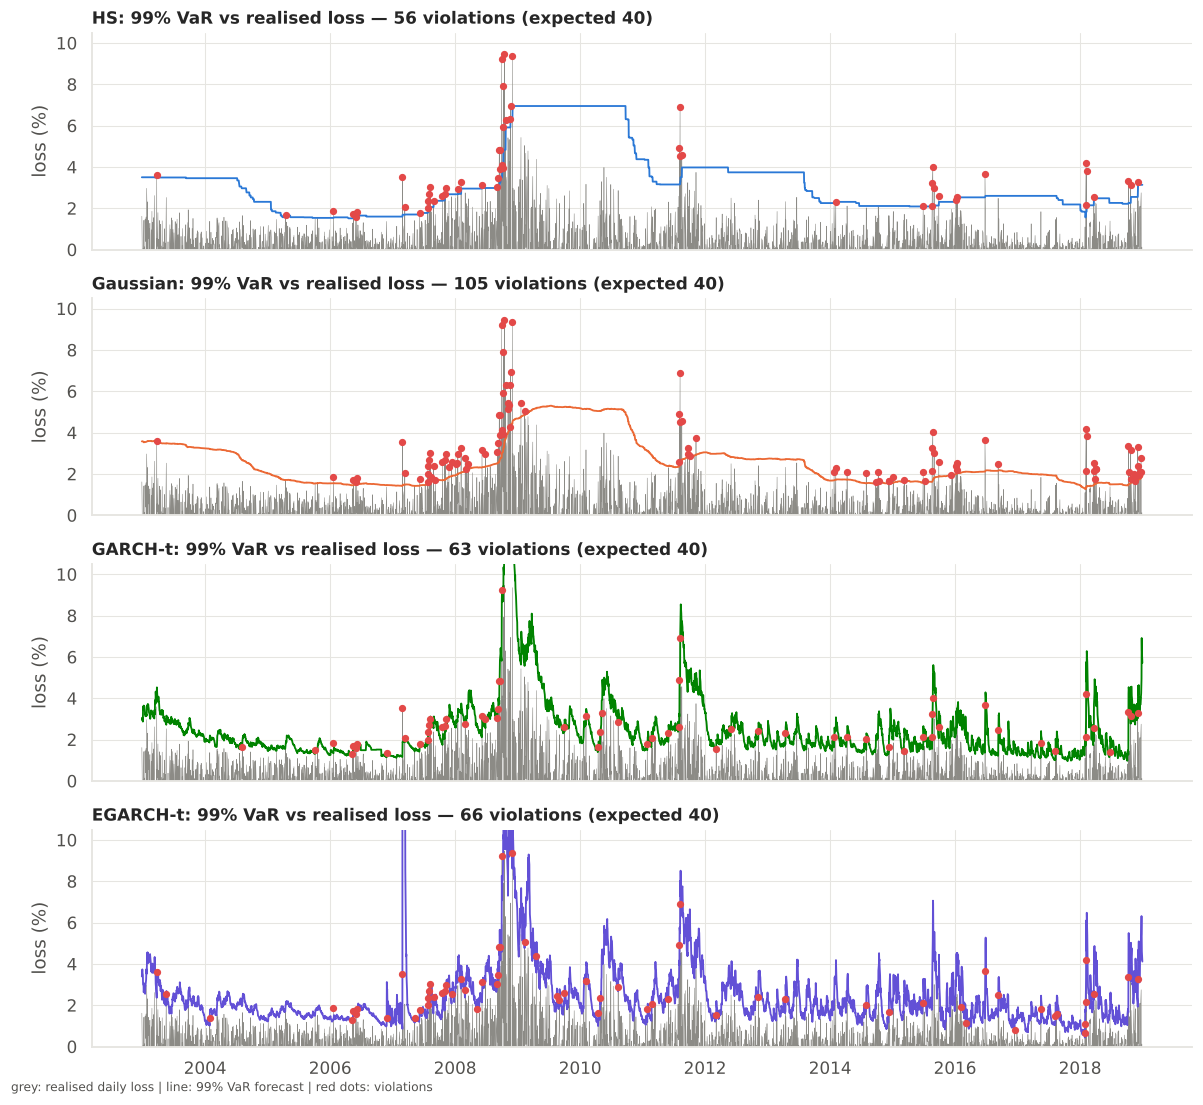

In [26]:
SHOW = ["HS", "Gaussian", "GARCH-t", "EGARCH-t"]
fig, axes = plt.subplots(len(SHOW), 1, figsize=(11, 10), sharex=True, sharey=True)
for ax, m in zip(axes, SHOW):
    v99 = fc[(m, 0.99)][0]
    hits = L_oos > v99
    ax.plot(oos_dates, 100 * L_oos, color=PAL["muted"], lw=0.35)
    ax.plot(oos_dates, 100 * v99, color=MODEL_COLOR[m] if m != "EGARCH-t" else PAL["violet"], lw=1.2)
    ax.scatter(oos_dates[hits], 100 * L_oos[hits], s=14, color=PAL["red"], zorder=3)
    ax.set_title(f"{m}: 99% VaR vs realised loss — {hits.sum()} violations (expected {len(hits) * 0.01:.0f})")
    ax.set_ylabel("loss (%)"); ax.set_ylim(0, None)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
fig.text(0.01, 0.003, "grey: realised daily loss | line: 99% VaR forecast | red dots: violations", fontsize=8, color=PAL["ink2"])
fig.tight_layout(); plt.show()

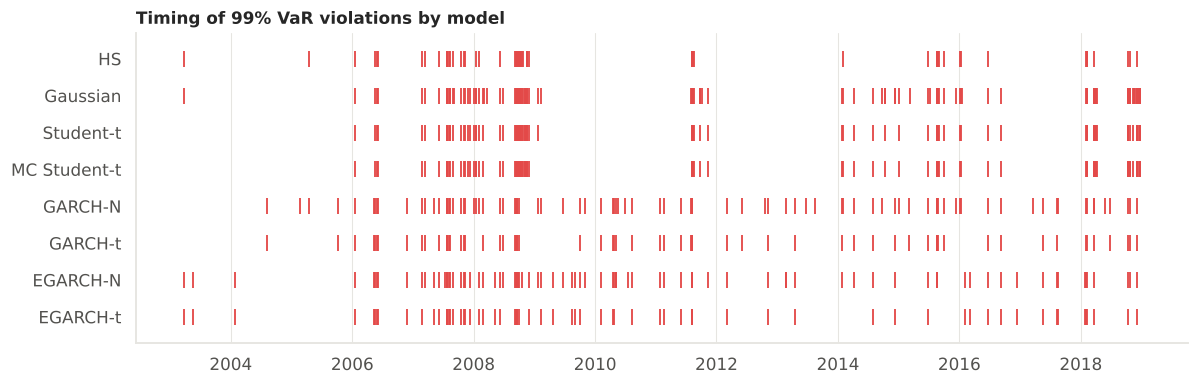

In [27]:
# Violation timeline ("barcode") for every benchmark model, 99 %
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, m in enumerate(MODELS_BENCH[::-1]):
    hits = L_oos > fc[(m, 0.99)][0]
    ax.scatter(oos_dates[hits], np.full(hits.sum(), i), marker="|", s=120, color=PAL["red"], lw=1.2)
ax.set_yticks(range(len(MODELS_BENCH))); ax.set_yticklabels(MODELS_BENCH[::-1])
ax.set_ylim(-0.7, len(MODELS_BENCH) - 0.3); ax.grid(axis="y", visible=False)
ax.set_title("Timing of 99% VaR violations by model")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
fig.tight_layout(); plt.show()

### 9.2 Calm vs stressed markets

**Ex-ante regime classification.** Day $t$ is labelled *stressed* if the trailing 21-day realised volatility measured at $t-1$ exceeds the 80th percentile of all trailing-volatility values observed up to $t-1$ (expanding, minimum one year). Because the label is $\mathcal F_{t-1}$-measurable, a correctly specified conditional VaR must deliver the nominal violation rate **in both regimes**: $\mathbb P(I_t = 1 \mid \text{regime}_t) = p$. Classifying days by *realised* volatility on day $t$ would condition on the outcome and bias every model towards failure in the stressed bucket.

13:16:56 | INFO    | Ex-ante regimes: 547 stressed days (13.6%), 3483 calm days


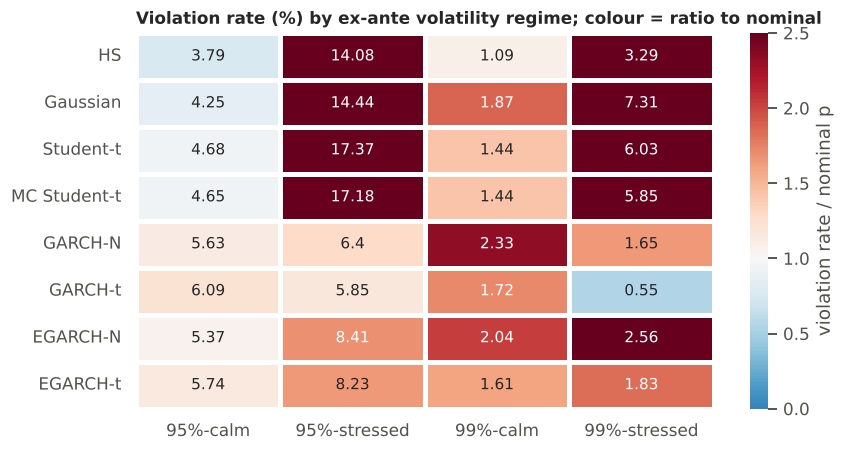

alpha            95%              99%         
regime          calm stressed    calm stressed
model                                         
HS            0.0006   0.0000  0.5947   0.0000
Gaussian      0.0371   0.0000  0.0000   0.0000
Student-t     0.3811   0.0000  0.0153   0.0000
MC Student-t  0.3394   0.0000  0.0153   0.0000
GARCH-N       0.0956   0.1495  0.0000   0.1652
GARCH-t       0.0044   0.3738  0.0001   0.2458
EGARCH-N      0.3233   0.0008  0.0000   0.0022
EGARCH-t      0.0494   0.0015  0.0009   0.0810

In [28]:
trail_vol = returns.rolling(21).std().shift(1)                       # uses r_{t-21..t-1}
thresh = trail_vol.expanding(min_periods=252).quantile(0.80)          # uses trail_vol up to t (itself F_{t-1})
stressed = (trail_vol > thresh).to_numpy()[OOS_IDX]
log.info("Ex-ante regimes: %d stressed days (%.1f%%), %d calm days", stressed.sum(), 100 * stressed.mean(), (~stressed).sum())

rows = []
for a in ALPHAS:
    p = tail_prob(a)
    for m in MODELS_BENCH:
        hits = L_oos > fc[(m, a)][0]
        for reg, mask in (("calm", ~stressed), ("stressed", stressed)):
            k = kupiec_pof(hits[mask], p)
            rows.append({"alpha": f"{a:.0%}", "model": m, "regime": reg, "days": int(mask.sum()),
                         "viol. %": 100 * k["rate"], "Kupiec p": k["p_uc"]})
reg_tbl = pd.DataFrame(rows)
piv = reg_tbl.pivot_table(index="model", columns=["alpha", "regime"], values="viol. %").loc[MODELS_BENCH]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(piv / np.array([100 * tail_prob(float(a.strip("%")) / 100) for a, _ in piv.columns]), annot=piv.round(2).to_numpy(),
            fmt="", cmap="RdBu_r", center=1, vmin=0, vmax=2.5, cbar_kws={"label": "violation rate / nominal p"},
            linewidths=2, linecolor="white", ax=ax)
ax.set_title("Violation rate (%) by ex-ante volatility regime; colour = ratio to nominal")
ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); plt.show()
display(reg_tbl.pivot_table(index="model", columns=["alpha", "regime"], values="Kupiec p").loc[MODELS_BENCH].round(4))

In [29]:
EPISODES = {
    "GFC (Sep 2008 - Mar 2009)": ("2008-09-01", "2009-03-31"),
    "US downgrade / euro crisis (Aug - Oct 2011)": ("2011-08-01", "2011-10-31"),
    "China devaluation (Aug - Sep 2015)": ("2015-08-17", "2015-09-30"),
    "Volmageddon & Q4 sell-off (2018)": ("2018-02-01", "2018-12-31"),
    "COVID crash (Feb - Apr 2020)": ("2020-02-20", "2020-04-30"),
    "Rate shock (2022)": ("2022-01-03", "2022-12-30"),
}
rows = []
for ep, (s, e) in EPISODES.items():
    mask = (oos_dates >= s) & (oos_dates <= e)
    if mask.sum() < 20:
        log.info("Episode %s not (sufficiently) covered by the out-of-sample period: skipped", ep)
        continue
    row = {"episode": ep, "days": int(mask.sum()), "expected @99%": round(mask.sum() * 0.01, 1)}
    for m in MODELS_BENCH:
        row[m] = int((L_oos[mask] > fc[(m, 0.99)][0][mask]).sum())
    rows.append(row)
ep_tbl = pd.DataFrame(rows).set_index("episode")
print("Number of 99% VaR violations during named stress episodes")
display(ep_tbl)

13:16:56 | INFO    | Episode COVID crash (Feb - Apr 2020) not (sufficiently) covered by the out-of-sample period: skipped


13:16:56 | INFO    | Episode Rate shock (2022) not (sufficiently) covered by the out-of-sample period: skipped


Number of 99% VaR violations during named stress episodes


,days,expected @99%,HS,Gaussian,Student-t,MC Student-t,GARCH-N,GARCH-t,EGARCH-N,EGARCH-t
episode,,,,,,,,,,
GFC (Sep 2008 - Mar 2009),146,1.5,15,21,19,18,7,5,10,7
US downgrade / euro crisis (Aug - Oct 2011),65,0.6,4,8,5,5,3,3,2,2
China devaluation (Aug - Sep 2015),32,0.3,5,5,5,5,4,4,2,0
Volmageddon & Q4 sell-off (2018),230,2.3,7,21,17,18,9,7,6,5


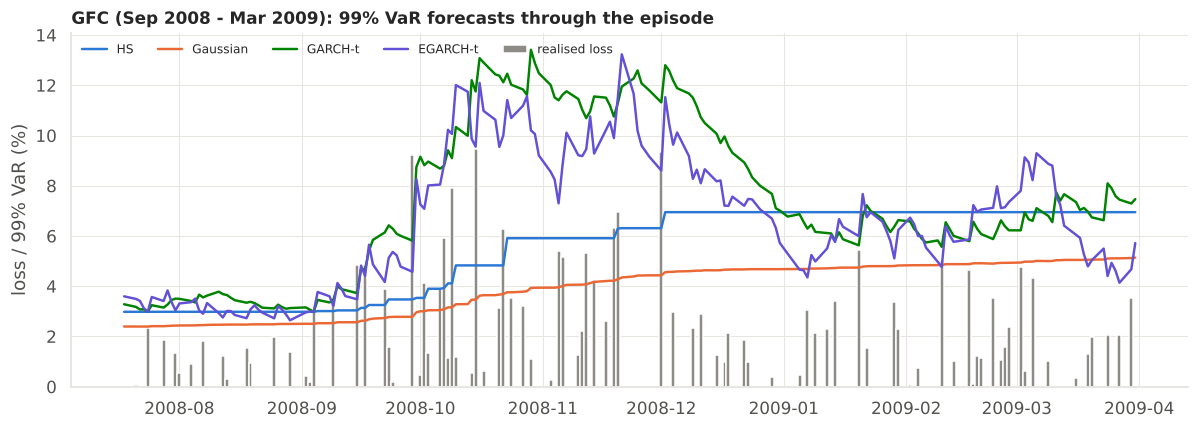

In [30]:
# Zoom on the worst stress episode covered: VaR forecasts side by side
ep_name = ep_tbl.index[0] if len(ep_tbl) else None
if ep_name:
    s, e = EPISODES[ep_name]
    s = (pd.Timestamp(s) - pd.Timedelta(days=45)).strftime("%Y-%m-%d")
    mask = (oos_dates >= s) & (oos_dates <= e)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(oos_dates[mask], 100 * np.clip(L_oos[mask], 0, None), width=1.0, color=PAL["muted"], label="realised loss")
    for m, c in (("HS", PAL["blue"]), ("Gaussian", PAL["orange"]), ("GARCH-t", PAL["green"]), ("EGARCH-t", PAL["violet"])):
        ax.plot(oos_dates[mask], 100 * fc[(m, 0.99)][0][mask], color=c, lw=1.6, label=m)
    ax.set_ylabel("loss / 99% VaR (%)"); ax.legend(ncol=5, fontsize=8, loc="upper left")
    ax.set_title(f"{ep_name}: 99% VaR forecasts through the episode")
    fig.tight_layout(); plt.show()

### 9.3 Conservatism, calibration and predictive performance

* **Correct counts are not enough.** A model can produce almost exactly $Tp$ violations over the whole period and still be badly specified. Too few violations in calm years and too many in crises cancel in the total, and only the independence/DQ tests, the regime split and the episode table reveal it. This is the textbook failure of historical simulation and of unconditional parametric models.
* **Conservatism is not calibration.** A larger average VaR mechanically reduces violations but ties up capital in calm periods and still fails in stress if it does not react. The average-VaR column must be read together with the coverage tests and the scores.
* **Scores rank models; tests screen them.** Coverage tests answer a yes/no question about one property. The FZ0 score (strictly consistent for VaR and ES jointly) rewards forecasts that are *sharp* and *calibrated* at the same time, and the Diebold–Mariano test says whether score differences are larger than sampling noise. A model should first pass the screening tests and then be ranked by score.

## 10. Adaptive Hybrid VaR: Quantitative Extension

### 10.1 Motivation

The backtest separates two sources of error:

1. **Volatility dynamics.** Unconditional models fail mainly here; GARCH-type models fix it.
2. **Innovation shape.** GARCH-N assumes Gaussian $z_t$; GARCH-t assumes a *symmetric* unit-variance t. The standardised residuals of equity indices are, however, **negatively skewed**: the left tail of $z_t$ is heavier than the right, even after volatility filtering.

The hybrid keeps the GARCH volatility forecast and replaces the parametric innovation distribution with the **empirical distribution of recent standardised residuals**, re-standardised at every refit. It belongs to the filtered-historical-simulation family (Hull & White, 1998; Barone-Adesi, Giannopoulos & Vosper, 1999). The "adaptive" elements are explicit: the scale adapts daily through $\hat\sigma_t$, and the tail shape adapts through a rolling residual window re-built with the latest parameters.

### 10.2 Specification

At refit date $t_k$, GARCH(1,1) with a constant mean is estimated by **Gaussian QMLE** on $y_{t_k-W}, \dots, y_{t_k-1}$ ($W$ = `W_EST` = 1,000). QMLE is consistent for $(\mu, \omega, \alpha, \beta)$ without assuming a shape for $z_t$, which is why it is the right first stage for a nonparametric second stage. These are exactly the GARCH-N fits of Section 7: the hybrid and GARCH-N share **identical** $\hat\mu$ and $\hat\sigma_t$, so any difference in performance is attributable to the innovation quantile alone.

For each target day $t$ in the block $[t_k, t_k+21)$:

1. **Standardised residuals** with the current parameters $\hat\theta_{t_k}$: $\hat z_s = (y_s - \hat\mu)/\hat\sigma_s(\hat\theta_{t_k})$ for $s = t-M, \dots, t-1$, quantile window $M$ = `RESID_WINDOW` = 1,000. Each $\hat\sigma_s$ is filtered with data up to $s-1$, and every $s < t$.
2. **Empirical tail** of $\{\hat z_s\}$ with the Section 4 estimator: $\hat q_z(p) = \hat z_{(k)}$, $k = \lceil Mp \rceil$, and $\widehat{\mathrm{ES}}_z(p)$ the exact empirical tail mean.
3. **Forecast** $\hat\sigma_t$ from the GARCH recursion (data up to $t-1$).
4. **Combine** (percent units, converted to decimals):
$$\mathrm{VaR}^{H}_{\alpha,t} = -\big(\hat\mu + \hat\sigma_t\,\hat q_z(p)\big), \qquad \mathrm{ES}^{H}_{\alpha,t} = -\hat\mu + \hat\sigma_t\,\widehat{\mathrm{ES}}_z(p).$$

**Methodological safeguards.**

* *No future residuals:* the window for target $t$ ends at $t-1$. The look-ahead test of Section 7 covers the residual filter, because residuals are produced by the same causal recursion.
* *Parameter estimation effect:* residuals are re-standardised with $\hat\theta_{t_k}$, not stored from earlier fits, so a refit consistently re-scales the whole window. Residuals inside the estimation window are in-sample with respect to $\hat\theta_{t_k}$ and are slightly less dispersed than true innovations (a known small-sample effect of FHS). The residuals of the first few days of each window also depend on the variance initialisation (backcast).
* *Tail sample size:* with $M = 1{,}000$ the 99% quantile rests on 10 residuals and the 99% ES on the 10 most negative ones. Volatility filtering makes these residuals far more homogeneous than raw returns, which is why a 1,000-day *residual* window is less stale than a 1,000-day *return* window.

13:16:57 | INFO    | Hybrid forecasts built from 192 GARCH-N blocks (residual window 1000)


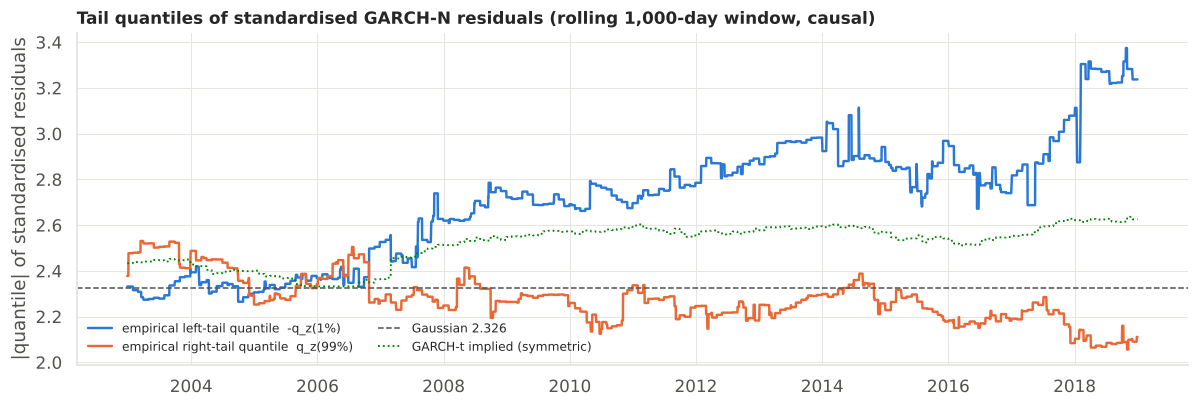

13:16:57 | INFO    | Mean |q_z| left 1%: 2.706 | right 99%: 2.279 | Gaussian: 2.326


In [31]:
def hybrid_from_blocks(blocks: list[dict], run_mu: np.ndarray, run_sigma: np.ndarray, alpha: float, M: int = RESID_WINDOW):
    """Filtered-historical VaR/ES (percent units) from GARCH-N blocks: empirical tail of the last M std. residuals."""
    v_out, e_out, zq_out = np.full(len(run_sigma), np.nan), np.full(len(run_sigma), np.nan), np.full(len(run_sigma), np.nan)
    for b in blocks:
        targets = np.arange(b["t_k"], b["block_end"])
        local_end = targets - b["g0"]                           # residual window = local positions [end-M, end)
        if (local_end - M).min() < 0:
            raise ValueError("residual window exceeds available residuals")
        z = b["z"]
        assert len(z) >= local_end.max(), "residuals missing for the last origin"
        zwin = sliding_window_view(z, M)[local_end - M]          # rows end at origin t-1 (local index end-1)
        vz, ez = empirical_var_es(zwin, alpha)                   # positive: -q_z and ES_z
        sl = slice(targets[0] - T0, targets[-1] - T0 + 1)
        v_out[sl] = -run_mu[sl] + run_sigma[sl] * vz
        e_out[sl] = -run_mu[sl] + run_sigma[sl] * ez
        zq_out[sl] = -vz
    return v_out, e_out, zq_out


run_n = garch_runs["GARCH-N"]
hyb_zq = {}
for a in ALPHAS:
    v_h, e_h, hyb_zq[a] = hybrid_from_blocks(run_n["blocks"], run_n["mu"], run_n["sigma"], a)
    fc[("Hybrid", a)] = (v_h / 100.0, e_h / 100.0)
    assert np.isfinite(v_h).all() and (e_h >= v_h - 1e-12).all()
log.info("Hybrid forecasts built from %d GARCH-N blocks (residual window %d)", len(run_n["blocks"]), RESID_WINDOW)

# Right-tail quantile of the same residual windows, to measure asymmetry
_, _, zq_right = hybrid_from_blocks([{**b, "z": -b["z"]} for b in run_n["blocks"]], run_n["mu"], run_n["sigma"], 0.99)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(oos_dates, -hyb_zq[0.99], color=PAL["blue"], lw=1.6, label="empirical left-tail quantile  -q_z(1%)")
ax.plot(oos_dates, -zq_right, color=PAL["orange"], lw=1.6, label="empirical right-tail quantile  q_z(99%)")
ax.axhline(-stats.norm.ppf(0.01), color=PAL["ink2"], lw=1, ls="--", label="Gaussian 2.326")
ax.plot(oos_dates, -std_t_ppf(0.01, garch_runs["GARCH-t"]["nu"]), color=PAL["green"], lw=1.2, ls=":", label="GARCH-t implied (symmetric)")
ax.set_ylabel("|quantile| of standardised residuals")
ax.set_title("Tail quantiles of standardised GARCH-N residuals (rolling 1,000-day window, causal)")
ax.legend(fontsize=8, ncol=2, loc="lower left")
fig.tight_layout(); plt.show()
log.info("Mean |q_z| left 1%%: %.3f | right 99%%: %.3f | Gaussian: 2.326", np.mean(-hyb_zq[0.99]), np.mean(-zq_right))

### 10.3 Backtest of the hybrid against the benchmarks

In [32]:
MODELS_ALL = MODELS_BENCH + ["Hybrid"]
rng_boot_h = np.random.default_rng(SEED + 4)
bt = pd.concat([bt, pd.DataFrame([backtest("Hybrid", a, *fc[("Hybrid", a)], rng_boot_h) for a in ALPHAS])
                .set_index(["alpha", "model"])]).sort_index(level=0, sort_remaining=False)

rows = []
for a in ALPHAS:
    p = tail_prob(a)
    loss_h = fz0_loss(r_oos, *fc[("Hybrid", a)], p)
    ql_h = quantile_loss(r_oos, fc[("Hybrid", a)][0], p)
    for m in ("HS", "Gaussian", "Student-t", "GARCH-N", "GARCH-t", "EGARCH-t"):
        dm, dmp = diebold_mariano(loss_h, fz0_loss(r_oos, *fc[(m, a)], p))
        dmq, dmqp = diebold_mariano(ql_h, quantile_loss(r_oos, fc[(m, a)][0], p))
        rows.append({"alpha": f"{a:.0%}", "Hybrid vs": m, "FZ0 diff": loss_h.mean() - fz0_loss(r_oos, *fc[(m, a)], p).mean(),
                     "DM (FZ0)": dm, "p (FZ0)": dmp, "DM (QL)": dmq, "p (QL)": dmqp})
dm_tbl = pd.DataFrame(rows).set_index(["alpha", "Hybrid vs"])
print("Diebold-Mariano tests, Hybrid minus benchmark (negative statistic = Hybrid better)")
display(dm_tbl.round(4))

hyb_rows = bt.xs("Hybrid", level="model")[["x", "expected", "rate", "p_uc", "p_ind", "p_cc", "p_dq_mc", "p_es", "FZ0"]]
display(hyb_rows.round(4))

rows = []
for a in ALPHAS:
    hits = L_oos > fc[("Hybrid", a)][0]
    for reg, mask in (("calm", ~stressed), ("stressed", stressed)):
        k = kupiec_pof(hits[mask], tail_prob(a))
        rows.append({"alpha": f"{a:.0%}", "regime": reg, "viol. %": 100 * k["rate"], "Kupiec p": k["p_uc"]})
print("Hybrid: violation rate by ex-ante regime")
display(pd.DataFrame(rows).set_index(["alpha", "regime"]).round(4))

Diebold-Mariano tests, Hybrid minus benchmark (negative statistic = Hybrid better)


FZ0 diff  DM (FZ0)  p (FZ0)  DM (QL)  p (QL)
alpha Hybrid vs                                              
95%   HS          -0.2432   -6.3440   0.0000  -5.2495  0.0000
      Gaussian    -0.3061   -5.9309   0.0000  -5.3643  0.0000
      Student-t   -0.3063   -5.8957   0.0000  -4.8803  0.0000
      GARCH-N     -0.0197   -1.9424   0.0521  -0.0752  0.9401
      GARCH-t     -0.0086   -0.8382   0.4019   0.1356  0.8922
      EGARCH-t    -0.0206   -0.9334   0.3506  -1.1157  0.2646
99%   HS          -0.3484   -4.2052   0.0000  -4.3241  0.0000
      Gaussian    -0.8039   -4.4737   0.0000  -4.1385  0.0000
      Student-t   -0.4726   -4.5341   0.0000  -4.1832  0.0000
      GARCH-N     -0.1449   -3.2195   0.0013  -2.3286  0.0199
      GARCH-t     -0.0212   -1.2716   0.2035  -0.7183  0.4726
      EGARCH-t    -0.0946   -1.7547   0.0793  -1.3387  0.1807

,x,expected,rate,p_uc,p_ind,p_cc,p_dq_mc,p_es,FZ0
alpha,,,,,,,,,
0.95,187,201.5,0.0464,0.2890,0.6455,0.5147,0.0495,0.0041,-3.8492
0.99,50,40.3,0.0124,0.1388,0.1572,0.1227,0.0010,0.0674,-3.4678


Hybrid: violation rate by ex-ante regime


viol. %  Kupiec p
alpha regime                     
95%   calm       4.7086    0.4257
      stressed   4.2048    0.3808
99%   calm       1.3207    0.0698
      stressed   0.7313    0.5071

### 10.4 Final comparison table (all models)

In [33]:
final_tbl = comparison_table(bt, MODELS_ALL)
display(final_tbl.round(3))

for a in ALPHAS:
    sub = final_tbl.loc[f"{a:.0%}"]
    ranking = sub["FZ0"].sort_values()
    log.info("alpha=%s FZ0 ranking (best first): %s", f"{a:.0%}", " > ".join(ranking.index))

T  violations  viol. %  expected  Kupiec p  Ind. p   CC p  DQ p (MC)  ES test p  avg VaR %  avg ES %  QL (bp)    FZ0  DM vs HS   DM p  tests passed (of 4)
alpha model                                                                                                                                                                      
95%   HS            4030         209    5.186     201.5     0.590   0.000  0.000      0.000      0.000      1.804     2.599   14.176 -3.606       NaN    NaN                    1
      Gaussian      4030         227    5.633     201.5     0.071   0.000  0.000      0.000      0.000      1.782     2.241   14.275 -3.543     3.890  0.000                    1
      Student-t     4030         258    6.402     201.5     0.000   0.000  0.000      0.000      0.000      1.606     2.418   14.475 -3.543     3.479  0.001                    0
      MC Student-t  4030         256    6.352     201.5     0.000   0.000  0.000      0.000      0.000      1.607     2.419   14.467 -3.543     3.465  0.001                    0
      GARCH-N       4030         231    5.732     201.5     0.037   0.943  0.112      0.014      0.000      1.583     1.999   11.811 -3.830    -5.992  0.000                    2
      GARCH-t       4030         244    6.055     201.5     0.003   0.828  0.011      0.001      0.006      1.544     2.139   11.795 -3.841    -5.951  0.000                    1
      EGARCH-N      4030         233    5.782     201.5     0.026   0.461  0.064      0.017      0.000      1.560     1.958   11.768 -3.835    -5.912  0.000                    2
      EGARCH-t      4030         245    6.079     201.5     0.002   0.262  0.005      0.007      0.000      1.784     2.392   13.001 -3.829    -5.123  0.000                    1
      Hybrid        4030         187    4.640     201.5     0.289   0.646  0.515      0.049      0.004      1.722     2.315   11.806 -3.849    -6.344  0.000                    3
99%   HS            4030          56    1.390      40.3     0.019   0.001  0.000      0.000      0.001      3.203     3.858    4.644 -3.119       NaN    NaN                    0
      Gaussian      4030         105    2.605      40.3     0.000   0.000  0.000      0.000      0.000      2.530     2.901    5.278 -2.664     3.893  0.000                    0
      Student-t     4030          83    2.060      40.3     0.000   0.000  0.000      0.000      0.388      2.820     3.964    4.985 -2.995     3.265  0.001                    0
      MC Student-t  4030          82    2.035      40.3     0.000   0.000  0.000      0.000      0.256      2.827     3.965    4.947 -2.992     3.215  0.001                    0
      GARCH-N       4030          90    2.233      40.3     0.000   0.505  0.000      0.000      0.000      2.261     2.597    3.552 -3.323    -2.409  0.016                    1
      GARCH-t       4030          63    1.563      40.3     0.001   0.095  0.001      0.000      0.360      2.479     3.143    3.362 -3.447    -3.861  0.000                    1
      EGARCH-N      4030          85    2.109      40.3     0.000   0.400  0.000      0.000      0.000      2.209     2.532    3.617 -3.295    -1.929  0.054                    1
      EGARCH-t      4030          66    1.638      40.3     0.000   0.420  0.001      0.001      0.016      2.749     3.383    3.765 -3.373    -2.497  0.013                    1
      Hybrid        4030          50    1.241      40.3     0.139   0.157  0.123      0.001      0.067      2.643     3.195    3.337 -3.468    -4.205  0.000                    3

13:16:58 | INFO    | alpha=95% FZ0 ranking (best first): Hybrid > GARCH-t > EGARCH-N > GARCH-N > EGARCH-t > HS > Gaussian > MC Student-t > Student-t


13:16:58 | INFO    | alpha=99% FZ0 ranking (best first): Hybrid > GARCH-t > EGARCH-t > GARCH-N > EGARCH-N > HS > Student-t > MC Student-t > Gaussian


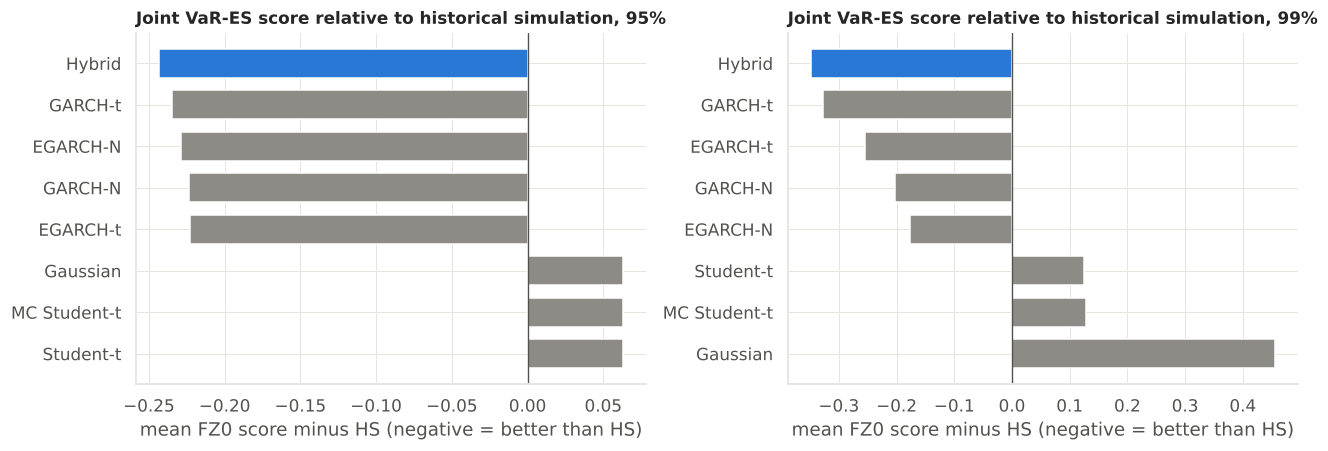

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, a in zip(axes, ALPHAS):
    sub = final_tbl.loc[f"{a:.0%}"]
    diff = (sub["FZ0"] - sub.loc["HS", "FZ0"]).drop("HS").sort_values()
    ax.barh(range(len(diff)), diff, height=0.7,
            color=[PAL["blue"] if m == "Hybrid" else PAL["muted"] for m in diff.index])
    ax.axvline(0, color=PAL["ink2"], lw=0.9)
    ax.set_yticks(range(len(diff))); ax.set_yticklabels(diff.index); ax.invert_yaxis()
    ax.set_xlabel("mean FZ0 score minus HS (negative = better than HS)")
    ax.set_title(f"Joint VaR-ES score relative to historical simulation, {a:.0%}")
fig.tight_layout(); plt.show()

## 11. Conclusions and Limitations

*The discussion refers to the reference run whose outputs are saved in this notebook (dataset printed in the run summary at the end of this section). The run summary is regenerated on every execution, so after re-running on another dataset the narrative should be checked against it.*

### 11.1 Answer to the research question

* **Coverage and clustering.** Model quality is governed first by whether the forecast *conditions on the current volatility state*. Historical simulation and unconditional parametric models can hit roughly the right number of violations over a long sample (HS at 95%: 209 vs 201.5 expected, Kupiec p = 0.59) while being badly wrong at every point in time: too conservative in calm years, far too permissive in crises. Only the independence, DQ and regime-conditional tests reveal it. Such a model would pass a frequency-only backtest and fail exactly when it matters.
* **Tail-risk forecasting.** Among conditional models, the innovation distribution decides the 99% tail. Gaussian innovations are clearly rejected. Symmetric Student-t innovations fix most of the 99% under-coverage but trade it against over-violation at 95%. The empirical residual distribution of the hybrid captures the asymmetry that neither parametric choice can.
* **Stress periods.** In the ex-ante stressed regime, unconditional models breach their 99% VaR 3–7 times more often than nominal. Conditional models stay much closer to nominal (0.6–2.6%) and re-price risk within days of a volatility shock, as the 2008 zoom illustrates. GARCH-type models are, however, *too permissive in calm periods* (99% violation rates of 1.6–2.3% in the calm regime). In long calm windows the t-likelihood drives $\nu$ towards infinity, so the tails become Gaussian just before volatility returns.
* **Model ranking.** By the strictly consistent FZ0 score: Hybrid > GARCH-t > GARCH-type models > HS > unconditional parametric models. Score differences between GARCH-type models are small and often not significant (Diebold–Mariano). Differences between conditional and unconditional models are large and significant.

### 11.2 A model-validation reading

A validation function would not "approve" any of these models from this evidence alone. The hybrid is the strongest candidate, but its DQ rejection at 99% points to residual dependence at lags 2–4 (violations a few days apart in crises). This is consistent with volatility forecasts that adjust too slowly after a jump, and with monthly re-estimation. The natural next steps are a faster-reacting volatility specification (or more frequent refits) rather than heavier tails. The exercise also illustrates validation practices that generalise beyond this dataset:

* **"Converged" is not "valid".** Optimiser success flags hid boundary solutions, degenerate means and a non-invertible EGARCH. Admissibility checks, and forecasting with an *unclipped* recursion that exposes instability, were necessary. Every fallback is logged.
* **Use exact or simulated reference distributions when events are rare.** At 99% the asymptotic $\chi^2$ critical values of the DQ test are visibly too small; Monte Carlo p-values are cheap and exact under the null.
* **Score, don't just count.** Coverage tests screen; strictly consistent scoring functions rank. ES must be evaluated jointly with VaR (FZ0), not with VaR coverage tests.
* **Look-ahead is tested, not asserted.** Overwriting future returns with noise and requiring bit-identical past forecasts is a simple, decisive leakage test.

### 11.3 Limitations

* **Single linear exposure.** One equity index proxies for a portfolio. Non-linear instruments, cross-asset correlations and liquidity horizons are absent, and results on SPY (with dividends) will differ in detail from the index-level reference run.
* **One horizon and two levels.** 1-day VaR at 95% and 99% only. FRTB capital uses ES at 97.5% with liquidity-horizon scaling, and its desk-level backtesting adds the 97.5% VaR level.
* **Fixed design choices.** Window lengths (500/1,000 days), monthly refits, a constant conditional mean and (E)GARCH(1,1) orders were fixed a priori. They are reasonable but not optimised, and other choices would change individual p-values.
* **Statistical power and multiplicity.** About 40 expected violations at 99% leave little power for fine distinctions; many tests on 9 models make some rejections expected by chance alone.
* **ES evaluation.** The exceedance-residual test is conditional on the VaR and uses few observations at 99%. The FZ0 ranking is sample-specific. Acerbi–Székely (2014) tests were not implemented.
* **Hybrid design.** With 1,000 residuals the 99% tail rests on ten observations, and in-sample standardised residuals are slightly less dispersed than true innovations.

### 11.4 Further research

1. **Skewed parametric benchmark.** GJR-GARCH with Hansen's skewed-t, to test whether the hybrid's gain can be achieved parametrically.
2. **EVT tail.** GARCH–EVT (McNeil & Frey, 2000): a generalised Pareto tail fitted to the standardised residuals, to stabilise the 99%+ quantile and ES.
3. **Regulatory horizon.** 97.5% ES on 10-day horizons with overlapping-window backtests, aligned with FRTB.
4. **Portfolio level.** Multivariate filtered historical simulation (DCC) on a multi-asset portfolio, including option positions revalued in full.
5. **Direct quantile models.** CAViaR / quantile-regression VaR, plus Murphy diagrams to check whether the ranking is robust across all consistent scoring functions.

In [35]:
# Data-driven summary of the run, printed so that the narrative can be checked against the numbers
for a in ALPHAS:
    sub = final_tbl.loc[f"{a:.0%}"]
    passes = sub.index[(sub[["Kupiec p", "CC p", "DQ p (MC)"]] > SIG).all(axis=1)].tolist()
    print(f"alpha = {a:.0%} | out-of-sample days: {int(sub['T'].iloc[0])} | expected violations: {sub['expected'].iloc[0]:.1f}")
    print(f"  pass Kupiec, CC and DQ at {SIG:.0%}:  {passes if passes else 'none'}")
    print(f"  FZ0 ranking (best first):   {list(sub['FZ0'].sort_values().index)}")
    print(f"  violations:                 {sub['violations'].to_dict()}")
print(f"\nDataset: {DATA_LABEL}; out-of-sample {oos_dates[0].date()} -> {oos_dates[-1].date()}")

alpha = 95% | out-of-sample days: 4030 | expected violations: 201.5
  pass Kupiec, CC and DQ at 5%:  none
  FZ0 ranking (best first):   ['Hybrid', 'GARCH-t', 'EGARCH-N', 'GARCH-N', 'EGARCH-t', 'HS', 'Gaussian', 'MC Student-t', 'Student-t']
  violations:                 {'HS': 209, 'Gaussian': 227, 'Student-t': 258, 'MC Student-t': 256, 'GARCH-N': 231, 'GARCH-t': 244, 'EGARCH-N': 233, 'EGARCH-t': 245, 'Hybrid': 187}
alpha = 99% | out-of-sample days: 4030 | expected violations: 40.3
  pass Kupiec, CC and DQ at 5%:  none
  FZ0 ranking (best first):   ['Hybrid', 'GARCH-t', 'EGARCH-t', 'GARCH-N', 'EGARCH-N', 'HS', 'Student-t', 'MC Student-t', 'Gaussian']
  violations:                 {'HS': 56, 'Gaussian': 105, 'Student-t': 83, 'MC Student-t': 82, 'GARCH-N': 90, 'GARCH-t': 63, 'EGARCH-N': 85, 'EGARCH-t': 66, 'Hybrid': 50}

Dataset: S&P 500 index, arch-bundled fallback (Yahoo Finance, 1999-2018); out-of-sample 2002-12-27 -> 2018-12-31


## 12. References

* Acerbi, C. & Székely, B. (2014). Backtesting Expected Shortfall. *Risk*, December.
* Acerbi, C. & Tasche, D. (2002). On the coherence of Expected Shortfall. *Journal of Banking & Finance*, 26(7), 1487–1503.
* Barone-Adesi, G., Giannopoulos, K. & Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets*, 19(5), 583–602.
* Basel Committee on Banking Supervision (1996). *Supervisory framework for the use of "backtesting" in conjunction with the internal models approach to market risk capital requirements.*
* Basel Committee on Banking Supervision (2019). *Minimum capital requirements for market risk* (FRTB, MAR 32: backtesting and P&L attribution).
* Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
* Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
* Diebold, F. X. & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
* Dufour, J.-M. (2006). Monte Carlo tests with nuisance parameters: A general approach to finite-sample inference and nonstandard asymptotics. *Journal of Econometrics*, 133(2), 443–477.
* Engle, R. F. & Manganelli, S. (2004). CAViaR: Conditional autoregressive value at risk by regression quantiles. *Journal of Business & Economic Statistics*, 22(4), 367–381.
* Fissler, T. & Ziegel, J. F. (2016). Higher order elicitability and Osband's principle. *Annals of Statistics*, 44(4), 1680–1707.
* Hull, J. & White, A. (1998). Incorporating volatility updating into the historical simulation method for value-at-risk. *Journal of Risk*, 1(1), 5–19.
* Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
* McNeil, A. J. & Frey, R. (2000). Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach. *Journal of Empirical Finance*, 7(3–4), 271–300.
* McNeil, A. J., Frey, R. & Embrechts, P. (2015). *Quantitative Risk Management: Concepts, Techniques and Tools* (revised ed.). Princeton University Press.
* Nelson, D. B. (1991). Conditional heteroskedasticity in asset returns: A new approach. *Econometrica*, 59(2), 347–370.
* Newey, W. K. & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.
* Patton, A. J., Ziegel, J. F. & Chen, R. (2019). Dynamic semiparametric models for expected shortfall (and value-at-risk). *Journal of Econometrics*, 211(2), 388–413.
* Straumann, D. & Mikosch, T. (2006). Quasi-maximum-likelihood estimation in conditionally heteroscedastic time series: a stochastic recurrence equations approach. *Annals of Statistics*, 34(5), 2449–2495.
* Wintenberger, O. (2013). Continuous invertibility and stable QML estimation of the EGARCH(1,1) model. *Scandinavian Journal of Statistics*, 40(4), 846–867.